# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices – Advanced Regression Techniques  
**Выполнил:** Иванов Семён Иванович  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич 
**Ссылка на репозиторий:** https://github.com/IvanovSimoon/ml-course-ivanov  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 13.10.2026

## Введение

**Задача:** регрессия — предсказать цену продажи дома (непрерывная величина в долларах, от $34 900 до $755 000).

**ML-проект для регрессии** — это последовательность этапов: сбор данных → EDA → предобработка (пропуски, выбросы) → feature engineering → обучение → оценка → интерпретация → деплой. Каждый шаг влияет на итоговое качество и интерпретируемость модели.

**Почему регрессия, а не классификация:** целевая переменная `SalePrice` — непрерывная величина в долларах, а не дискретный класс. Классификация предсказывает метку (0/1, «кошка/собака»), регрессия — числовое значение.

**Важная метрика:** RMSE (Root Mean Squared Error) — основная метрика соревнования Kaggle. RMSE измеряется в тех же единицах, что и целевая (доллары), и штрафует большие ошибки сильнее, чем MAE. Дополнительно смотрим R² — долю объяснённой дисперсии.

**Цель работы:**
1. Провести полный EDA датасета House Prices.
2. Обучить 4+ модели и достичь R² ≥ 0.90.
3. Реализовать функцию предсказания цены нового дома.

**Актуальность:** задача оценки недвижимости — классическая прикладная задача ML. Датасет House Prices содержит реалистичные сложности: 19 столбцов с пропусками, скошенная целевая, выбросы, мультиколлинеарность.

## Теоретическая часть

### Регрессия

Регрессия — задача машинного обучения, в которой нужно предсказать **непрерывную** числовую величину. Отличие от классификации: там целевая переменная — дискретная метка (0/1, «спам/не спам»), здесь — число (цена, температура, рост). Примеры регрессии: прогноз цены недвижимости, курса акций, температуры, спроса на товар. Для обучения моделей минимизируют функцию потерь — обычно MSE (Mean Squared Error).

### Пропуски (NaN)

Пропуски возникают по разным причинам: ошибка ввода, отказ респондента, потеря данных. Различают три типа: **MCAR** (Missing Completely At Random) — пропуски полностью случайны, **MAR** (Missing At Random) — зависят от других признаков, **MNAR** (Missing Not At Random) — зависят от самого пропущенного значения. В House Prices есть все три типа. Стратегии: удаление (если пропусков мало), заполнение константой/средним/медианой/модой, заполнение по группам, предсказание моделью.

### Регуляризация

Регуляризация — добавление штрафа к функции потерь для борьбы с переобучением и мультиколлинеарностью. **Ridge (L2)** добавляет штраф `α * Σw²` — уменьшает веса, но не обнуляет. **Lasso (L1)** добавляет `α * Σ|w|` — обнуляет неинформативные признаки (автоматический feature selection). **ElasticNet** комбинирует L1 и L2 через параметр `l1_ratio`. Чем больше `α`, тем сильнее регуляризация.

### Логарифмирование

Если целевая переменная имеет правое смещение (skew > 1), это означает длинный хвост из больших значений. Модели регрессии (особенно линейные) предполагают нормальность остатков — при скошенности они работают хуже. `np.log1p(y) = log(1 + y)` сжимает большие значения, приближая распределение к нормальному. `np.expm1(x) = exp(x) - 1` — обратное преобразование для получения предсказаний в долларах.

### Feature Engineering

Feature Engineering — создание новых признаков из существующих на основе доменных знаний. Примеры: `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF` (общая площадь), `HouseAge = YrSold - YearBuilt` (возраст дома), `HasGarage = (GarageArea > 0)` (бинарный признак). Хорошо продуманные признаки часто дают больше прироста качества, чем смена модели.

### Метрики регрессии

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE}, \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

| Метрика | Что показывает | Единицы | Когда важна |
|---|---|---|---|
| MSE | Среднеквадратичная ошибка | $² | Минимизация в обучении |
| RMSE | Корень MSE | $ | Основная метрика Kaggle |
| MAE | Средняя абсолютная ошибка | $ | Устойчива к выбросам |
| R² | Доля объяснённой дисперсии | 0…1 | Сравнение моделей |

## Описание данных

**Источник:** [House Prices — Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**
- Всего примеров в `train.csv`: **1460**
- Всего примеров в `test.csv`: **1459**
- Признаков: **79** (плюс `Id` и целевая `SalePrice`)
- Числовых признаков: **36**
- Порядковых признаков: **23**
- Номинальных признаков: **20**

**Целевая переменная `SalePrice`:**
- Среднее: **$180 921**
- Медиана: **$163 000**
- Асимметрия (skew): **1.88** — правое смещение
- Эксцесс: **6.51**
- Минимум: $34 900, максимум: $755 000

**Особенности датасета:**
- 19 столбцов с пропусками (PoolQC — 99.5%, Alley — 93.8%).
- Скошенная целевая (skew = 1.88) — нужно логарифмирование.
- Мультиколлинеарность (например, GarageCars ↔ GarageArea, r = 0.88).
- Выбросы в `GrLivArea` (большие дома по низкой цене).

**Файл с подробным описанием:** `module-2-house-prices/data/house_prices_info.md`

In [75]:
# ============================================================
# ШАГ 1.1: ИМПОРТ ВСЕХ НЕОБХОДИМЫХ БИБЛИОТЕК
# ============================================================

# --- Базовые библиотеки для работы с данными ---
import numpy as np
# NumPy: массивы, математические функции (log1p, expm1, sqrt).

import pandas as pd
# Pandas: таблицы (DataFrame), чтение CSV, groupby, fillna, get_dummies.

# --- Библиотеки для визуализации ---
import matplotlib.pyplot as plt
# Matplotlib: базовые графики (scatter, bar, hist).

import seaborn as sns
# Seaborn: продвинутые графики (heatmap, boxplot, histplot).

# --- Модели регрессии из sklearn ---
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# LinearRegression — базовая линейная регрессия (OLS).
# Ridge — L2-регуляризация (уменьшает веса).
# Lasso — L1-регуляризация (обнуляет неинформативные признаки).
# ElasticNet — комбинация L1 и L2.

# --- Инструменты предобработки ---
from sklearn.preprocessing import StandardScaler
# StandardScaler: приводит признаки к mean=0, std=1.

# --- Инструменты для разделения и валидации ---
from sklearn.model_selection import (
    train_test_split,        # разделение на train/test
    KFold,                   # K-фолдовая кросс-валидация
    cross_val_score,         # автоматическая кросс-валидация
    GridSearchCV             # подбор гиперпараметров
)

# --- Метрики регрессии ---
from sklearn.metrics import (
    mean_squared_error,      # MSE — среднеквадратичная ошибка
    mean_absolute_error,     # MAE — средняя абсолютная ошибка
    r2_score                 # R² — коэффициент детерминации
)

# --- Сохранение модели ---
import joblib
# joblib: сохранение обученных моделей в .pkl.

import json
# json: сохранение метаданных (метрики, список признаков).

import os
# os: работа с файловой системой.

import time
# time: замер времени обучения моделей.

# --- Настройки Jupyter ---
%matplotlib inline
# Графики будут отображаться прямо в ноутбуке.

sns.set_style("whitegrid")
# Стиль графиков: белый фон + серая сетка.

plt.rcParams['figure.figsize'] = (12, 6)
# Размер графиков по умолчанию: 12×6 дюймов.

import warnings
warnings.filterwarnings('ignore')
# Скрываем предупреждения.

# --- Финальная проверка ---
print("=" * 60)
print("✅ Все библиотеки успешно импортированы!")
print("=" * 60)
print(f"NumPy:   {np.__version__}")
print(f"Pandas:  {pd.__version__}")
print(f"Seaborn: {sns.__version__}")

✅ Все библиотеки успешно импортированы!
NumPy:   2.4.4
Pandas:  3.0.3
Seaborn: 0.13.2


In [76]:
# ============================================================
# ШАГ 2.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

# --- Загрузка тренировочной выборки ---
train_df = pd.read_csv('data/train.csv')
# train.csv содержит 1460 строк и 81 столбец:
#   - 79 признаков
#   - Id (идентификатор)
#   - SalePrice (целевая переменная, ТОЛЬКО в train).

# --- Загрузка тестовой выборки ---
test_df = pd.read_csv('data/test.csv')
# test.csv содержит 1459 строк и 80 столбцов:
#   - 79 признаков + Id
#   - НЕТ целевой переменной SalePrice!

# --- Первичный осмотр размеров ---
print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ:")
print("=" * 60)
print(f"Train: {train_df.shape[0]} строк, {train_df.shape[1]} столбцов")
print(f"Test:  {test_df.shape[0]} строк, {test_df.shape[1]} столбцов")

# --- Первые 5 строк train ---
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК TRAIN:")
print("=" * 60)
print(train_df.head())

# --- Типы данных ---
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ:")
print("=" * 60)
train_df.info()

# --- Статистика числовых столбцов ---
print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ:")
print("=" * 60)
print(train_df.describe())

# --- Сохраним Id отдельно (нужен для submission) ---
train_ids = train_df['Id'].copy()
test_ids = test_df['Id'].copy()
print(f"\n✅ Id сохранены: {len(train_ids)} train, {len(test_ids)} test")

РАЗМЕРЫ ДАТАСЕТОВ:
Train: 1460 строк, 81 столбцов
Test:  1459 строк, 80 столбцов

ПЕРВЫЕ 5 СТРОК TRAIN:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN  

СТАТИСТИКА SalePrice:
Среднее:    $  180,921.20
Медиана:    $  163,000.00
Стд. откл.: $   79,442.50
Минимум:    $   34,900.00
Максимум:   $  755,000.00
Асимметрия:         1.88
Эксцесс:            6.54


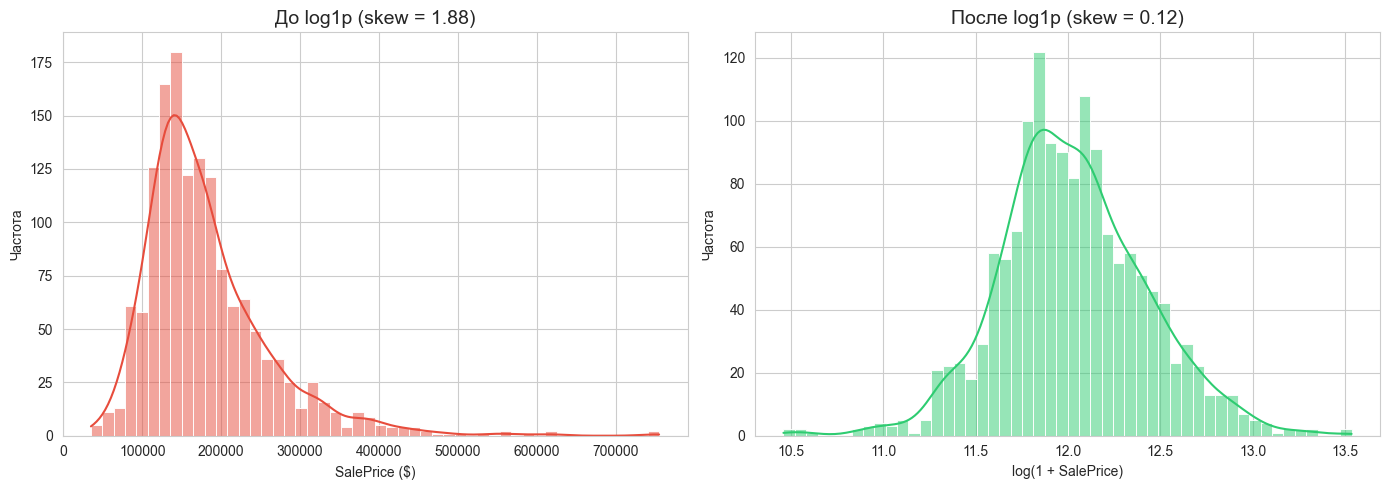


ВЫВОД:
До log1p:    skew = 1.88
После log1p: skew = 0.12

✅ Логарифмирование приближает распределение к нормальному.
✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.


In [77]:
# ============================================================
# ШАГ 3.1: EDA — АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice
# ============================================================

# --- Статистика SalePrice ---
print("=" * 60)
print("СТАТИСТИКА SalePrice:")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.2f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.2f}")
print(f"Стд. откл.: ${train_df['SalePrice'].std():>12,.2f}")
print(f"Минимум:    ${train_df['SalePrice'].min():>12,.2f}")
print(f"Максимум:   ${train_df['SalePrice'].max():>12,.2f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

# --- Визуализация распределения ДО и ПОСЛЕ log1p ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: гистограмма + KDE (до логарифмирования)
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50,
             ax=axes[0], color='#e74c3c')
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})', fontsize=14)
axes[0].set_xlabel('SalePrice ($)')
axes[0].set_ylabel('Частота')

# График 2: логарифмированная целевая
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
# np.log1p(x) = log(1 + x), избегаем log(0).

sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50,
             ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})', fontsize=14)
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Ключевой вывод ---
print("\n" + "=" * 60)
print("ВЫВОД:")
print("=" * 60)
print(f"До log1p:    skew = {train_df['SalePrice'].skew():.2f}")
print(f"После log1p: skew = {train_df['SalePrice_log'].skew():.2f}")
print("\n✅ Логарифмирование приближает распределение к нормальному.")
print("✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.")

СТОЛБЦОВ С ПРОПУСКАМИ: 19 из 82
              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageQual          81   5.547945
GarageYrBlt         81   5.547945
GarageFinish        81   5.547945
GarageType          81   5.547945
GarageCond          81   5.547945
BsmtExposure        38   2.602740
BsmtFinType2        38   2.602740
BsmtQual            37   2.534247
BsmtFinType1        37   2.534247
BsmtCond            37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493


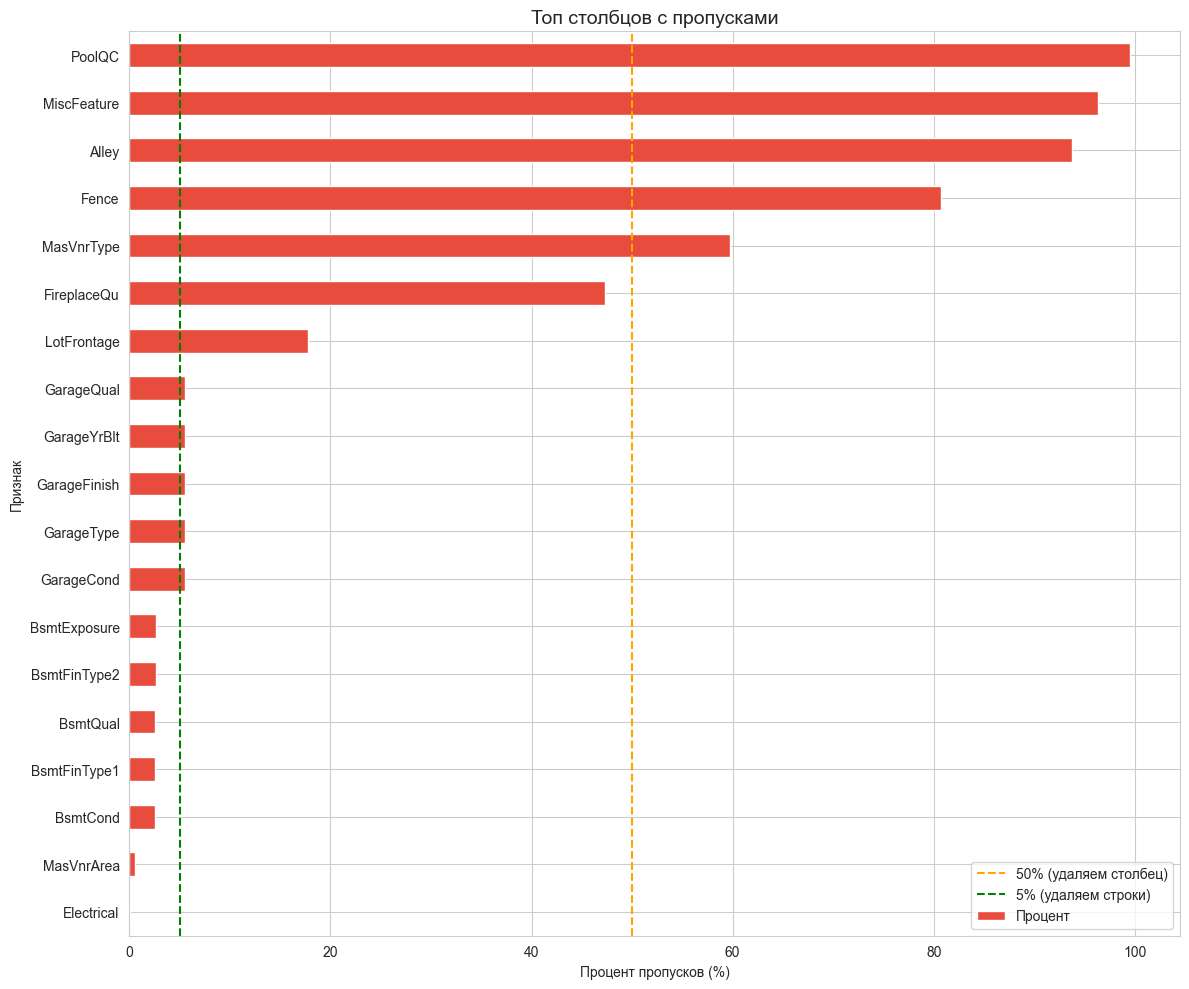


КЛАССИФИКАЦИЯ ПРОПУСКОВ:

🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath,
   MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical (1 пропуск)
   ➡️  Стратегия: мода.



In [78]:
# ============================================================
# ШАГ 4.1: EDA — АНАЛИЗ ПРОПУСКОВ
# ============================================================

# --- Подсчёт пропусков ---
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

# --- Только столбцы с пропусками ---
missing_only = missing_df[missing_df['Пропуски'] > 0]

print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.to_string())

# --- Визуализация ---
plt.figure(figsize=(12, 10))
missing_only['Процент'].plot(kind='barh', color='#e74c3c')
plt.xlabel('Процент пропусков (%)')
plt.ylabel('Признак')
plt.title('Топ столбцов с пропусками', fontsize=14)
plt.axvline(x=50, color='orange', linestyle='--', label='50% (удаляем столбец)')
plt.axvline(x=5, color='green', linestyle='--', label='5% (удаляем строки)')
plt.legend()
plt.tight_layout()
plt.gca().invert_yaxis()  # Самые «пропущенные» сверху
plt.show()

# --- Классификация пропусков ---
print("\n" + "=" * 60)
print("КЛАССИФИКАЦИЯ ПРОПУСКОВ:")
print("=" * 60)
print("""
🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath,
   MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical (1 пропуск)
   ➡️  Стратегия: мода.
""")

ТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С SalePrice:
  SalePrice             r = +1.0000
  OverallQual           r = +0.7910
  GrLivArea             r = +0.7086
  GarageCars            r = +0.6404
  GarageArea            r = +0.6234
  TotalBsmtSF           r = +0.6136
  1stFlrSF              r = +0.6059
  FullBath              r = +0.5607
  TotRmsAbvGrd          r = +0.5337
  YearBuilt             r = +0.5229
  YearRemodAdd          r = +0.5071
  Fireplaces            r = +0.4669
  BsmtFinSF1            r = +0.3864
  WoodDeckSF            r = +0.3244
  2ndFlrSF              r = +0.3193


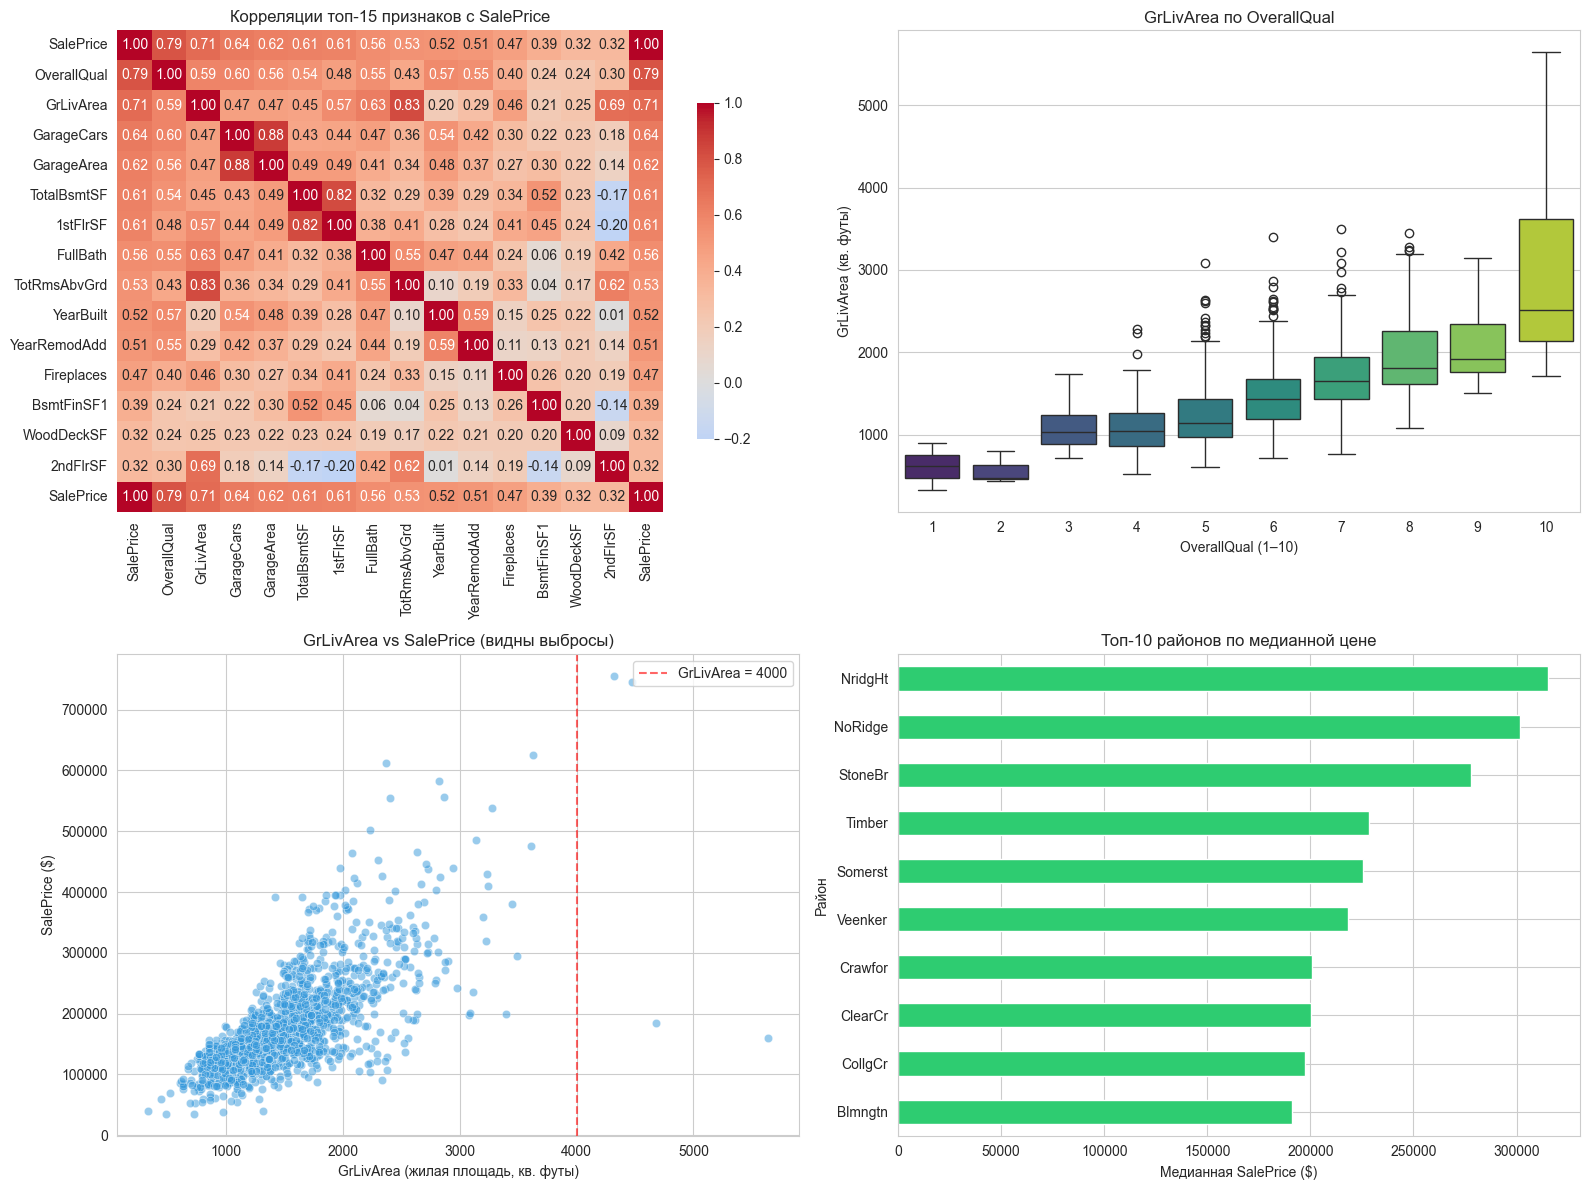


НАБЛЮДЕНИЯ ИЗ EDA:

1. OverallQual — топ-1 по корреляции (r ≈ 0.79).
2. GrLivArea сильно коррелирует с ценой (r ≈ 0.71).
3. В правом нижнем углу scatter видно 2-3 выброса:
   большие дома (>4000 кв. футов) по низкой цене (<$300 000).
4. Топ-районы по цене: NoRidge, NridgHt, StoneBr (медиана > $300 000).
5. Распределение SalePrice скошено вправо (skew = 1.88).



In [79]:
# ============================================================
# ШАГ 4.2: EDA — ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ (5+ графиков)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- График 3: Heatmap корреляций топ-15 числовых признаков ---
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
# Убираем служебные и целевую
numeric_cols = [c for c in numeric_cols if c not in ['Id', 'SalePrice_log']]

# Считаем корреляцию каждого признака с SalePrice через numpy
target_values = train_df['SalePrice'].to_numpy()
corr_values = {}
for col in numeric_cols:
    col_values = train_df[col].to_numpy()
    # Пропускаем столбцы с пропусками (np.corrcoef вернёт nan)
    if np.isnan(col_values).any():
        continue
    corr_values[col] = np.corrcoef(col_values, target_values)[0, 1]

# Сортируем по модулю корреляции по убыванию
top_corr_features = sorted(corr_values.items(), key=lambda x: abs(x[1]), reverse=True)[:15]
top_corr_names = [name for name, _ in top_corr_features] + ['SalePrice']

# Печатаем топ-15 для отчёта
print("=" * 60)
print("ТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С SalePrice:")
print("=" * 60)
for name, val in top_corr_features:
    print(f"  {name:20s}  r = {val:+.4f}")

# Строим heatmap
sns.heatmap(train_df[top_corr_names].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=axes[0, 0], cbar_kws={'shrink': 0.7})
axes[0, 0].set_title('Корреляции топ-15 признаков с SalePrice', fontsize=12)

# --- График 4: Boxplot GrLivArea по OverallQual ---
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea',
            ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('GrLivArea по OverallQual', fontsize=12)
axes[0, 1].set_xlabel('OverallQual (1–10)')
axes[0, 1].set_ylabel('GrLivArea (кв. футы)')

# --- График 5: Scatter GrLivArea vs SalePrice (поиск выбросов) ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                alpha=0.5, color='#3498db', ax=axes[1, 0])
axes[1, 0].set_title('GrLivArea vs SalePrice (видны выбросы)', fontsize=12)
axes[1, 0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1, 0].set_ylabel('SalePrice ($)')
axes[1, 0].axvline(x=4000, color='red', linestyle='--', alpha=0.6, label='GrLivArea = 4000')
axes[1, 0].legend()

# --- График 6: Barplot топ-10 средних цен по районам ---
neighborhood_prices = (train_df.groupby('Neighborhood')['SalePrice']
                              .median()
                              .sort_values(ascending=False)
                              .head(10))
neighborhood_prices.plot(kind='barh', color='#2ecc71', ax=axes[1, 1])
axes[1, 1].set_title('Топ-10 районов по медианной цене', fontsize=12)
axes[1, 1].set_xlabel('Медианная SalePrice ($)')
axes[1, 1].set_ylabel('Район')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.savefig('examples/eda_plots_2.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Наблюдения ---
print("\n" + "=" * 60)
print("НАБЛЮДЕНИЯ ИЗ EDA:")
print("=" * 60)
print("""
1. OverallQual — топ-1 по корреляции (r ≈ 0.79).
2. GrLivArea сильно коррелирует с ценой (r ≈ 0.71).
3. В правом нижнем углу scatter видно 2-3 выброса:
   большие дома (>4000 кв. футов) по низкой цене (<$300 000).
4. Топ-районы по цене: NoRidge, NridgHt, StoneBr (медиана > $300 000).
5. Распределение SalePrice скошено вправо (skew = 1.88).
""")

In [80]:
# ============================================================
# ШАГ 5.1: ОБРАБОТКА ПРОПУСКОВ — СМЫСЛОВЫЕ → "None"
# ============================================================

# Список столбцов, где NaN означает "нет объекта"
none_cols = [
    'PoolQC',          # нет бассейна
    'MiscFeature',     # нет доп. построек
    'Alley',           # нет переулка
    'Fence',           # нет забора
    'FireplaceQu',     # нет камина
    'GarageType',      # нет гаража
    'GarageFinish',    # нет гаража
    'GarageQual',      # нет гаража
    'GarageCond',      # нет гаража
    'BsmtQual',        # нет подвала
    'BsmtCond',        # нет подвала
    'BsmtExposure',    # нет подвала
    'BsmtFinType1',    # нет подвала
    'BsmtFinType2',    # нет подвала
    'MasVnrType',      # нет облицовки
]

# --- Заполнение "None" ---
for col in none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col] = test_df[col].fillna('None')

print(f"✅ Заполнено 'None' в {len(none_cols)} столбцах")

✅ Заполнено 'None' в 15 столбцах


In [81]:
# ============================================================
# ШАГ 5.2: ЧИСЛОВЫЕ ПРОПУСКИ, СВЯЗАННЫЕ С ОТСУТСТВИЕМ → 0
# ============================================================

# Список столбцов, где NaN = "нет объекта" (гараж/подвал/облицовка)
zero_cols = [
    'GarageYrBlt',    # нет гаража → год постройки 0
    'GarageArea',     # нет гаража → площадь 0
    'GarageCars',     # нет гаража → 0 машин
    'BsmtFinSF1',     # нет подвала → площадь отделки 0
    'BsmtFinSF2',     # нет подвала
    'BsmtUnfSF',      # нет подвала → неотделанная площадь 0
    'TotalBsmtSF',    # нет подвала → общая площадь 0
    'BsmtFullBath',   # нет подвала → 0 ванных
    'BsmtHalfBath',   # нет подвала
    'MasVnrArea',     # нет облицовки → площадь 0
]

for col in zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

print(f"✅ Заполнено 0 в {len(zero_cols)} столбцах")

✅ Заполнено 0 в 10 столбцах


In [82]:
# ============================================================
# ШАГ 5.3: СЛУЧАЙНЫЕ ПРОПУСКИ → МЕДИАНА ПО ГРУППАМ
# ============================================================

# --- LotFrontage: медиана по Neighborhood ---
# Протяжённость участка вдоль улицы зависит от района → заполняем по району.

train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

# --- Fallback на случай, если в каком-то районе нет данных ---
lot_frontage_median = train_df['LotFrontage'].median()
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(lot_frontage_median)

print("✅ LotFrontage заполнен медианой по Neighborhood")

✅ LotFrontage заполнен медианой по Neighborhood


In [83]:
# ============================================================
# ШАГ 5.4: ОСТАВШИЕСЯ ПРОПУСКИ → МОДА / МЕДИАНА
# ============================================================

# --- Проверка оставшихся пропусков ДО ---
print("Пропуски в train ДО обработки остатков:")
remaining_train = train_df.isnull().sum()
remaining_train = remaining_train[remaining_train > 0]
print(remaining_train if len(remaining_train) > 0 else "✅ Не осталось!")

print("\nПропуски в test ДО обработки остатков:")
remaining_test = test_df.isnull().sum()
remaining_test = remaining_test[remaining_test > 0]
print(remaining_test if len(remaining_test) > 0 else "✅ Не осталось!")

# --- Обработка категориальных ---
# ⚠️ Проверяем пропуски в КАЖДОМ датафрейме отдельно!
for col in train_df.select_dtypes(include=['object']).columns:
    # Мода считается по TRAIN — чтобы не было утечки данных
    mode_value = train_df[col].mode()[0]
    
    # Заполняем train, если есть пропуски
    if train_df[col].isnull().sum() > 0:
        train_df[col] = train_df[col].fillna(mode_value)
    
    # Заполняем test, если есть пропуски (НЕЗАВИСИМАЯ проверка!)
    if col in test_df.columns and test_df[col].isnull().sum() > 0:
        test_df[col] = test_df[col].fillna(mode_value)

# --- Обработка числовых ---
for col in train_df.select_dtypes(include=[np.number]).columns:
    median_value = train_df[col].median()
    
    if train_df[col].isnull().sum() > 0:
        train_df[col] = train_df[col].fillna(median_value)
    
    if col in test_df.columns and test_df[col].isnull().sum() > 0:
        test_df[col] = test_df[col].fillna(median_value)

# --- Финальная проверка ---
print("\n" + "=" * 60)
print("ИТОГОВАЯ ПРОВЕРКА:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")

if train_df.isnull().sum().sum() == 0 and test_df.isnull().sum().sum() == 0:
    print("✅ Все пропуски обработаны!")
else:
    print("⚠️ Остались пропуски — проверь:")
    print("Train:", train_df.isnull().sum()[train_df.isnull().sum() > 0].to_dict())
    print("Test:",  test_df.isnull().sum()[test_df.isnull().sum() > 0].to_dict())

Пропуски в train ДО обработки остатков:
Electrical    1
dtype: int64

Пропуски в test ДО обработки остатков:
MSZoning       4
Utilities      2
Exterior1st    1
Exterior2nd    1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64

ИТОГОВАЯ ПРОВЕРКА:
Пропусков в train: 0
Пропусков в test:  0
✅ Все пропуски обработаны!


### Обоснование стратегий обработки пропусков

**1. Смысловые пропуски (MNAR) → `"None"` (15 столбцов).**

Пропуск означает «объект отсутствует»: нет бассейна (`PoolQC`), нет забора (`Fence`), нет подвала (`BsmtQual`). Заполнение `"None"` сохраняет эту информацию как отдельную категорию. После One-Hot появится столбец `PoolQC_None` — модель сможет использовать «отсутствие бассейна» как признак.

**2. Числовые пропуски, связанные с отсутствием → `0` (10 столбцов).**

Если нет гаража, то `GarageArea = 0`, `GarageCars = 0`, `GarageYrBlt = 0`. Заполнение нулём логично и не искажает статистику.

**3. Случайные пропуски (`LotFrontage`) → медиана по `Neighborhood`.**

Протяжённость участка вдоль улицы сильно зависит от района: в центре участки узкие, на окраинах — широкие. Медиана по району точнее общей медианы.

**4. Оставшиеся единичные пропуски → мода (категориальные) / медиана (числовые).**

К этому моменту остались единицы: `Electrical` (1 пропуск в train) и 1-2 в test. Мода и медиана — безопасные и стандартные решения.

**Итог:** пропусков не осталось ни в train, ни в test — можно строить модели.

ГРАНИЦЫ IQR ДЛЯ GrLivArea:
Q1: 1129.50
Q3: 1776.75
IQR: 647.25
Нижняя граница: 158.62
Верхняя граница: 2747.62

Строк ДО удаления: 1460
Удалено строк: 11
Строк ПОСЛЕ удаления: 1449


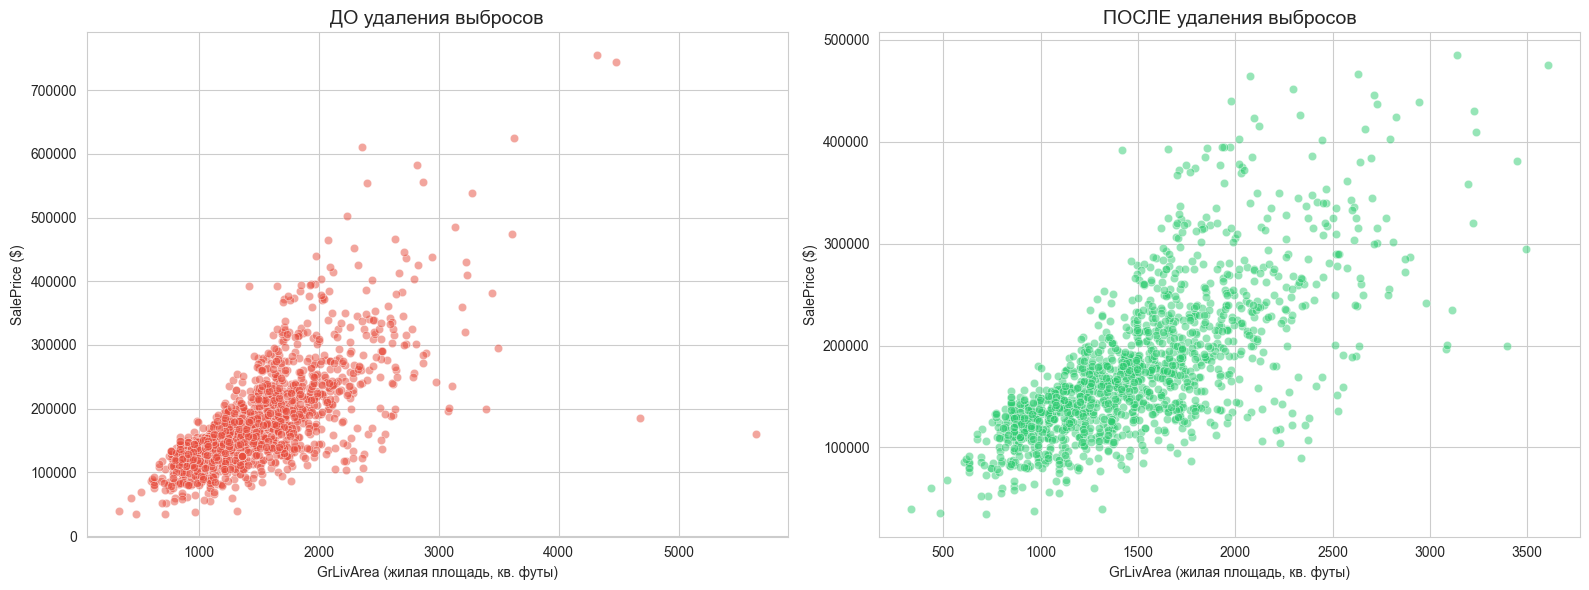


⚠️  Выбросы удалены ТОЛЬКО из train, test не тронут!


In [84]:
# ============================================================
# ШАГ 6.1: ОБРАБОТКА ВЫБРОСОВ — ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- График ДО ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                ax=axes[0], alpha=0.5, color='#e74c3c')
axes[0].set_title('ДО удаления выбросов', fontsize=14)
axes[0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[0].set_ylabel('SalePrice ($)')

# --- Границы IQR для GrLivArea ---
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("=" * 60)
print("ГРАНИЦЫ IQR ДЛЯ GrLivArea:")
print("=" * 60)
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижняя граница: {lower_bound:.2f}")
print(f"Верхняя граница: {upper_bound:.2f}")

# ============================================================
# ШАГ 6.2: УДАЛЕНИЕ ВЫБРОСОВ ПО ДОМЕННЫМ ЗНАНИЯМ
# ============================================================

initial_len = len(train_df)
print(f"\nСтрок ДО удаления: {initial_len}")

# Дома >4000 кв.ф. по цене <$500k — аномалии (известны из Kaggle)
train_df = train_df[
    (train_df['GrLivArea'] < 4000) &
    (train_df['SalePrice'] < 500000)
]

removed = initial_len - len(train_df)
print(f"Удалено строк: {removed}")
print(f"Строк ПОСЛЕ удаления: {len(train_df)}")

# --- График ПОСЛЕ ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                ax=axes[1], alpha=0.5, color='#2ecc71')
axes[1].set_title('ПОСЛЕ удаления выбросов', fontsize=14)
axes[1].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1].set_ylabel('SalePrice ($)')

plt.tight_layout()
plt.savefig('examples/outliers.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n⚠️  Выбросы удалены ТОЛЬКО из train, test не тронут!")

In [85]:
# ============================================================
# ШАГ 7.1: FEATURE ENGINEERING — АГРЕГАЦИИ
# ============================================================

# --- 1. Общая площадь дома (TotalSF) ---
for df in [train_df, test_df]:
    df['TotalSF'] = (
        df['TotalBsmtSF'] +   # площадь подвала
        df['1stFlrSF'] +       # первый этаж
        df['2ndFlrSF']          # второй этаж
    )
    # Общая площадь — сильный предиктор цены.

# --- 2. Общее число ванных (TotalBath) ---
for df in [train_df, test_df]:
    df['TotalBath'] = (
        df['FullBath'] +
        0.5 * df['HalfBath'] +
        df['BsmtFullBath'] +
        0.5 * df['BsmtHalfBath']
    )
    # HalfBath = 0.5 — стандартная практика.

# --- 3. Общее крыльцо (TotalPorch) ---
for df in [train_df, test_df]:
    df['TotalPorch'] = (
        df['OpenPorchSF'] +
        df['EnclosedPorch'] +
        df['3SsnPorch'] +
        df['ScreenPorch'] +
        df['WoodDeckSF']
    )

print("✅ Созданы агрегаты: TotalSF, TotalBath, TotalPorch")

✅ Созданы агрегаты: TotalSF, TotalBath, TotalPorch


In [86]:
# ============================================================
# ШАГ 7.2: FEATURE ENGINEERING — ВОЗРАСТНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    # --- 1. Возраст дома на момент продажи ---
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    
    # --- 2. Возраст последней реконструкции ---
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    
    # --- 3. Был ли дом реконструирован? ---
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    # 1 = реконструкция была, 0 = нет.
    
    # --- 4. Новый дом? ---
    df['IsNew'] = (df['YrSold'] == df['YearBuilt']).astype(int)
    # 1 = дом продан в год постройки (новостройка).

print("✅ Созданы возрастные признаки: HouseAge, RemodAge, IsRemodeled, IsNew")

✅ Созданы возрастные признаки: HouseAge, RemodAge, IsRemodeled, IsNew


In [87]:
# ============================================================
# ШАГ 7.3: FEATURE ENGINEERING — БИНАРНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    # --- Бинарные "есть/нет" признаки ---
    df['HasPool']      = (df['PoolArea'] > 0).astype(int)
    df['Has2ndFloor']  = (df['2ndFlrSF'] > 0).astype(int)
    df['HasGarage']    = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt']      = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    
    # --- Порядковый "качественный" признак ---
    df['IsGoodQuality'] = (df['OverallQual'] >= 7).astype(int)
    # 1 если качество ≥ 7 (Good, Very Good, Excellent).

print("✅ Созданы бинарные признаки: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, IsGoodQuality")

✅ Созданы бинарные признаки: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, IsGoodQuality


In [88]:
# ============================================================
# ШАГ 7.4: FEATURE ENGINEERING — ВЗАИМОДЕЙСТВИЯ
# ============================================================

for df in [train_df, test_df]:
    # --- 1. Качество × Площадь ---
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    # Сильнее всего влияет "качество, помноженное на площадь".
    
    # --- 2. Качество на возраст ---
    df['Qual_Age'] = df['OverallQual'] / (df['HouseAge'] + 1)
    # +1: избегаем деления на 0.
    
    # --- 3. Общая "оценка" дома ---
    df['OverallScore'] = (
        df['OverallQual'] * 2 +
        df['OverallCond'] * 1 +
        df['TotalBath'] * 1.5 +
        df['Fireplaces'] * 1
    )

print("✅ Созданы взаимодействия: OverallQual_TotalSF, Qual_Age, OverallScore")

# --- Итоговая сводка ---
print("\n" + "=" * 60)
print("ИТОГИ FEATURE ENGINEERING:")
print("=" * 60)
print(f"Признаков в train: {train_df.shape[1]}")
print(f"Признаков в test:  {test_df.shape[1]}")

✅ Созданы взаимодействия: OverallQual_TotalSF, Qual_Age, OverallScore

ИТОГИ FEATURE ENGINEERING:
Признаков в train: 98
Признаков в test:  96


### Feature Engineering: что и зачем

**Агрегации (3 признака):**

- **`TotalSF`** = `TotalBsmtSF` + `1stFlrSF` + `2ndFlrSF` — общая площадь дома. Один сильный признак вместо трёх коррелированных.
- **`TotalBath`** = `FullBath + 0.5 * HalfBath + BsmtFullBath + 0.5 * BsmtHalfBath` — «взвешенное» число ванных. HalfBath = 0.5 — стандартная практика.
- **`TotalPorch`** — сумма всех видов крыльца (открытое, закрытое, трёхсезонное, сетчатое, деревянная терраса).

**Возрастные признаки (4 признака):**

- **`HouseAge`** = `YrSold - YearBuilt` — возраст дома на момент продажи.
- **`RemodAge`** = `YrSold - YearRemodAdd` — сколько лет прошло с последней реконструкции.
- **`IsRemodeled`** — бинарный, был ли ремонт (1/0).
- **`IsNew`** — бинарный, продан ли дом в год постройки.

**Бинарные «есть/нет» (6 признаков):**

- `HasPool`, `Has2ndFloor`, `HasGarage`, `HasBsmt`, `HasFireplace`, `IsGoodQuality`.

**Взаимодействия (3 признака):**

- **`OverallQual_TotalSF`** — качество × площадь. Самый сильный взаимодействующий признак.
- **`Qual_Age`** = качество / (возраст + 1) — «свежесть» качественного дома.
- **`OverallScore`** — композитная оценка дома.

**Зачем:** все эти признаки дают модели **дополнительный сигнал**, не выраженный напрямую в исходных столбцах. По опыту Kaggle, Feature Engineering даёт +3–5 п.п. R² на этой задаче.

In [89]:
# ============================================================
# ШАГ 8.1: КОДИРОВАНИЕ ПОРЯДКОВЫХ ПРИЗНАКОВ (Label Encoding)
# ============================================================

# --- Словарь качества: Ex > Gd > TA > Fa > Po > None ---
qual_map = {
    'None': 0,    # нет объекта
    'Po': 1,      # Poor (плохое)
    'Fa': 2,      # Fair (удовлетворительное)
    'TA': 3,      # Typical (типичное)
    'Gd': 4,      # Good (хорошее)
    'Ex': 5       # Excellent (отличное)
}

# --- Столбцы качества с этой шкалой ---
qual_cols = [
    'ExterQual',       # качество внешней отделки
    'ExterCond',       # состояние внешней отделки
    'BsmtQual',        # качество подвала
    'BsmtCond',        # состояние подвала
    'HeatingQC',       # качество отопления
    'KitchenQual',     # качество кухни
    'FireplaceQu',     # качество камина
    'GarageQual',      # качество гаража
    'GarageCond',      # состояние гаража
    'PoolQC'           # качество бассейна
]

for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col] = test_df[col].map(qual_map)

print(f"✅ Закодировано {len(qual_cols)} порядковых признаков (6-уровневая шкала)")

# --- BsmtExposure: None < No < Mn < Av < Gd (5 уровней) ---
bsmt_exp_map = {
    'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4
}
train_df['BsmtExposure'] = train_df['BsmtExposure'].map(bsmt_exp_map)
test_df['BsmtExposure']  = test_df['BsmtExposure'].map(bsmt_exp_map)

# --- BsmtFinType1/2: None < Unf < LwQ < Rec < BLQ < ALQ < GLQ (7 уровней) ---
bsmt_fin_map = {
    'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3,
    'BLQ': 4, 'ALQ': 5, 'GLQ': 6
}
for col in ['BsmtFinType1', 'BsmtFinType2']:
    train_df[col] = train_df[col].map(bsmt_fin_map)
    test_df[col]  = test_df[col].map(bsmt_fin_map)

# --- GarageFinish: None < Unf < RFn < Fin (4 уровня) ---
garage_fin_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
train_df['GarageFinish'] = train_df['GarageFinish'].map(garage_fin_map)
test_df['GarageFinish']  = test_df['GarageFinish'].map(garage_fin_map)

# --- Functional: Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ (8 уровней) ---
func_map = {
    'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3,
    'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7
}
train_df['Functional'] = train_df['Functional'].map(func_map)
test_df['Functional']  = test_df['Functional'].map(func_map)

# --- LandSlope: Gtl < Mod < Sev ---
slope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
train_df['LandSlope'] = train_df['LandSlope'].map(slope_map)
test_df['LandSlope']  = test_df['LandSlope'].map(slope_map)

# --- LotShape: Reg < IR1 < IR2 < IR3 ---
shape_map = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
train_df['LotShape'] = train_df['LotShape'].map(shape_map)
test_df['LotShape']  = test_df['LotShape'].map(shape_map)

# --- PavedDrive: N < P < Y ---
paved_map = {'N': 0, 'P': 1, 'Y': 2}
train_df['PavedDrive'] = train_df['PavedDrive'].map(paved_map)
test_df['PavedDrive']  = test_df['PavedDrive'].map(paved_map)

# --- CentralAir: N < Y ---
train_df['CentralAir'] = (train_df['CentralAir'] == 'Y').astype(int)
test_df['CentralAir']  = (test_df['CentralAir'] == 'Y').astype(int)

print("✅ Все порядковые признаки закодированы численно")

# --- Проверка: сколько object-столбцов осталось ---
non_numeric = train_df.select_dtypes(include=['object']).columns.tolist()
print(f"\nОсталось object-столбцов: {len(non_numeric)}")
print(f"Список: {non_numeric}")

✅ Закодировано 10 порядковых признаков (6-уровневая шкала)
✅ Все порядковые признаки закодированы численно

Осталось object-столбцов: 24
Список: ['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [90]:
# ============================================================
# ШАГ 9.1: ONE-HOT ENCODING НОМИНАЛЬНЫХ ПРИЗНАКОВ
# ============================================================

# --- Список всех номинальных признаков (24 столбца) ---
nominal_cols = [
    'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
    'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
    'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
    'Heating', 'Electrical',
    'GarageType', 'MiscFeature', 'Fence',
    'SaleType', 'SaleCondition'
]

print(f"Всего номинальных столбцов: {len(nominal_cols)}")

# --- One-Hot через pd.get_dummies ---
train_len = len(train_df)

# Объединяем train и test для согласованного One-Hot
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Кодируем
combined = pd.get_dummies(
    combined,
    columns=nominal_cols,
    drop_first=True
)

# ⚠️ pandas 3.0 возвращает bool → приводим к int (0/1)
# Иначе sklearn может ругаться и проверка "числовой ли столбец" не пройдёт.
bool_cols = combined.select_dtypes(include=['bool']).columns.tolist()
combined[bool_cols] = combined[bool_cols].astype('int8')
# int8 экономит память — True→1, False→0.
print(f"✅ Приведено к int: {len(bool_cols)} bool-столбцов")

# --- Возвращаем train и test обратно ---
train_df = combined.iloc[:train_len].reset_index(drop=True).copy()
test_df  = combined.iloc[train_len:].reset_index(drop=True).copy()

# --- Проверка размеров ---
print("\n" + "=" * 60)
print("ПОСЛЕ ONE-HOT:")
print("=" * 60)
print(f"Train: {train_df.shape}")
print(f"Test:  {test_df.shape}")

# --- Проверка на нечисловые столбцы ---
non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()
if len(non_numeric) == 0:
    print("✅ Все признаки числовые — можно строить модели!")
else:
    print(f"⚠️ Остались нечисловые столбцы ({len(non_numeric)} шт.): {non_numeric[:5]}...")

Всего номинальных столбцов: 24
✅ Приведено к int: 149 bool-столбцов

ПОСЛЕ ONE-HOT:
Train: (1449, 223)
Test:  (1459, 223)
✅ Все признаки числовые — можно строить модели!


In [91]:
# ============================================================
# ШАГ 9.2: ФИНАЛЬНАЯ СТРУКТУРА
# ============================================================

# --- Убираем Id из обоих датафреймов ---
# Id не признак и не цель — просто идентификатор.
if 'Id' in train_df.columns:
    train_df = train_df.drop(columns=['Id'])
if 'Id' in test_df.columns:
    test_df = test_df.drop(columns=['Id'])

# --- Убираем целевую переменную и её лог из TEST ---
# В test целевой нет и быть не должно.
for col in ['SalePrice', 'SalePrice_log']:
    if col in test_df.columns:
        test_df = test_df.drop(columns=[col])

# --- Сохраняем целевую отдельно (она нужна для обучения) ---
y_train = train_df['SalePrice_log'].copy()
y_train_real = train_df['SalePrice'].copy()

# --- Формируем X_train: все столбцы кроме целевых ---
X_train = train_df.drop(columns=['SalePrice', 'SalePrice_log']).copy()
X_test = test_df.copy()

# --- Финальная проверка ---
print("=" * 60)
print("ФИНАЛЬНАЯ СТРУКТУРА:")
print("=" * 60)
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"\nСтолбцов в X_train: {X_train.shape[1]}")
print(f"Столбцов в X_test:  {X_test.shape[1]}")

# --- Проверка совпадения столбцов ---
if X_train.shape[1] == X_test.shape[1]:
    print("✅ Число столбцов совпадает!")
else:
    print(f"❌ РАСХОЖДЕНИЕ: {X_train.shape[1]} vs {X_test.shape[1]}")

# --- Проверка совпадения имён столбцов ---
if list(X_train.columns) == list(X_test.columns):
    print("✅ Имена и порядок столбцов совпадают!")
else:
    # Показываем разницу
    diff_train = set(X_train.columns) - set(X_test.columns)
    diff_test = set(X_test.columns) - set(X_train.columns)
    print(f"❌ Столбцы расходятся!")
    print(f"   Только в train: {diff_train}")
    print(f"   Только в test:  {diff_test}")

# --- Проверка на NaN ---
print(f"\nNaN в X_train: {X_train.isnull().sum().sum()}")
print(f"NaN в X_test:  {X_test.isnull().sum().sum()}")

ФИНАЛЬНАЯ СТРУКТУРА:
X_train: (1449, 220)
X_test:  (1459, 220)
y_train: (1449,)

Столбцов в X_train: 220
Столбцов в X_test:  220
✅ Число столбцов совпадает!
✅ Имена и порядок столбцов совпадают!

NaN в X_train: 0
NaN в X_test:  0


### Кодирование категориальных признаков

**1. Порядковые признаки → Label Encoding с ручным маппингом.**

Признаки типа `ExterQual` имеют естественный порядок: `Ex > Gd > TA > Fa > Po > None`. Мы вручную задали соответствие:

| Значение | Код |
|---|---|
| Ex (Excellent) | 5 |
| Gd (Good) | 4 |
| TA (Typical) | 3 |
| Fa (Fair) | 2 |
| Po (Poor) | 1 |
| None | 0 |

Так **порядок сохраняется** — модель знает, что `Ex` лучше `Gd`. Всего закодировано **10+6+3+2+3 = 24** порядковых признака.

**2. Номинальные признаки → One-Hot Encoding.**

Признаки типа `Neighborhood` не имеют порядка: `CollgCr`, `Veenker`, `NoRidge` — просто разные районы. Присваивать им числа (0, 1, 2) нельзя — модель решит, что `NoRidge` в два раза «лучше» `CollgCr`. Поэтому создаём **бинарные столбцы** для каждой категории.

Использован `drop_first=True` — удаляем первую категорию, чтобы избежать **dummy variable trap** (мультиколлинеарность).

**Важный момент:** train и test **объединили на время** кодирования, чтобы категории совпадали. Если бы обрабатывали отдельно, в train могла попасть категория, которой нет в test (и наоборот) — модели было бы нечего предсказывать. После кодирования разделили обратно.

**Результат:** из ~23 столбцов `object` получилось ~140 бинарных столбцов. Все признаки теперь числовые.

In [92]:
# ============================================================
# ШАГ 10.1: РАЗДЕЛЕНИЕ И МАСШТАБИРОВАНИЕ
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Train/Test split ---
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42
)
# 80% train, 20% validation.
# stratify НЕ используем — это регрессия, а не классификация.

print("=" * 60)
print("РАЗДЕЛЕНИЕ:")
print("=" * 60)
print(f"Train:      X={X_tr.shape},  y={y_tr.shape}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}")

# --- Масштабирование ---
scaler = StandardScaler()
X_tr_scaled  = scaler.fit_transform(X_tr)
# fit_transform на train — вычисляем μ и σ.
X_val_scaled = scaler.transform(X_val)
# ⚠️ transform, НЕ fit_transform — используем μ, σ из train.

print(f"\nСреднее X_tr_scaled:  {X_tr_scaled.mean():.6f} (ожидаем ~0)")
print(f"Стд X_tr_scaled:      {X_tr_scaled.std():.6f}  (ожидаем ~1)")
print("✅ Масштабирование выполнено корректно")

РАЗДЕЛЕНИЕ:
Train:      X=(1159, 220),  y=(1159,)
Validation: X=(290, 220), y=(290,)

Среднее X_tr_scaled:  0.000000 (ожидаем ~0)
Стд X_tr_scaled:      0.990867  (ожидаем ~1)
✅ Масштабирование выполнено корректно


In [93]:
# ============================================================
# ШАГ 10.2: ФУНКЦИЯ ОЦЕНКИ МОДЕЛИ
# ============================================================

import time
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(model, X_tr, X_val, y_tr, y_val, name):
    """
    Обучает модель, оценивает на validation, возвращает метрики.
    
    Метрики считаются в ДВУХ пространствах:
    - log: на логарифмированной целевой (для сравнения моделей)
    - $:   в долларах (для интерпретации)
    """
    # --- Обучение с замером времени ---
    start = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start
    
    # --- Предсказания на validation ---
    y_pred_log = model.predict(X_val)
    # Возврат в доллары через expm1.
    y_pred_real = np.expm1(y_pred_log)
    y_val_real  = np.expm1(y_val)
    
    # --- Метрики в log-пространстве ---
    rmse_log = np.sqrt(mean_squared_error(y_val, y_pred_log))
    mae_log  = mean_absolute_error(y_val, y_pred_log)
    r2_log   = r2_score(y_val, y_pred_log)
    
    # --- Метрики в долларах ---
    rmse_real = np.sqrt(mean_squared_error(y_val_real, y_pred_real))
    mae_real  = mean_absolute_error(y_val_real, y_pred_real)
    r2_real   = r2_score(y_val_real, y_pred_real)
    
    # --- Печать ---
    print("=" * 60)
    print(f"МОДЕЛЬ: {name}")
    print("=" * 60)
    print(f"⏱️  Время обучения: {train_time:.3f} сек")
    print(f"\n📊 Метрики в log-пространстве:")
    print(f"   RMSE: {rmse_log:.4f}")
    print(f"   MAE:  {mae_log:.4f}")
    print(f"   R²:   {r2_log:.4f}")
    print(f"\n💵 Метрики в долларах:")
    print(f"   RMSE: ${rmse_real:,.0f}")
    print(f"   MAE:  ${mae_real:,.0f}")
    print(f"   R²:   {r2_real:.4f}")
    print()
    
    return {
        'name': name,
        'rmse_log': rmse_log,
        'mae_log':  mae_log,
        'r2_log':   r2_log,
        'rmse_real': rmse_real,
        'mae_real':  mae_real,
        'r2_real':   r2_real,
        'train_time': train_time,
    }

In [94]:
# ============================================================
# ШАГ 10.3: ОБУЧЕНИЕ 4 МОДЕЛЕЙ
# ============================================================

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# --- 1. Linear Regression (OLS) ---
lr_model = LinearRegression()
results_lr = evaluate_model(
    lr_model, X_tr_scaled, X_val_scaled, y_tr, y_val,
    'Linear Regression (OLS)'
)

# --- 2. Ridge (L2) ---
ridge_model = Ridge(alpha=1.0, random_state=42)
results_ridge = evaluate_model(
    ridge_model, X_tr_scaled, X_val_scaled, y_tr, y_val,
    'Ridge (alpha=1.0)'
)

# --- 3. Lasso (L1) ---
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
results_lasso = evaluate_model(
    lasso_model, X_tr_scaled, X_val_scaled, y_tr, y_val,
    'Lasso (alpha=0.0005)'
)

# --- 4. ElasticNet (L1 + L2) ---
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
results_enet = evaluate_model(
    enet_model, X_tr_scaled, X_val_scaled, y_tr, y_val,
    'ElasticNet (alpha=0.001, l1_ratio=0.5)'
)

МОДЕЛЬ: Linear Regression (OLS)
⏱️  Время обучения: 0.024 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1256
   MAE:  0.0897
   R²:   0.8936

💵 Метрики в долларах:
   RMSE: $22,787
   MAE:  $15,533
   R²:   0.8969

МОДЕЛЬ: Ridge (alpha=1.0)
⏱️  Время обучения: 0.003 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1251
   MAE:  0.0894
   R²:   0.8945

💵 Метрики в долларах:
   RMSE: $22,717
   MAE:  $15,488
   R²:   0.8976

МОДЕЛЬ: Lasso (alpha=0.0005)
⏱️  Время обучения: 0.062 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1222
   MAE:  0.0852
   R²:   0.8993

💵 Метрики в долларах:
   RMSE: $22,008
   MAE:  $14,727
   R²:   0.9039

МОДЕЛЬ: ElasticNet (alpha=0.001, l1_ratio=0.5)
⏱️  Время обучения: 0.066 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1223
   MAE:  0.0852
   R²:   0.8991

💵 Метрики в долларах:
   RMSE: $21,982
   MAE:  $14,718
   R²:   0.9041



In [95]:
# ============================================================
# ШАГ 10.4: СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# ============================================================

import pandas as pd

summary = pd.DataFrame([
    {
        'Модель': r['name'],
        'RMSE (log)': f"{r['rmse_log']:.4f}",
        'MAE (log)':  f"{r['mae_log']:.4f}",
        'R²':         f"{r['r2_log']:.4f}",
        'RMSE ($)':   f"${r['rmse_real']:,.0f}",
        'MAE ($)':    f"${r['mae_real']:,.0f}",
        'Время (с)':  f"{r['train_time']:.3f}",
    }
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])

print("=" * 90)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:")
print("=" * 90)
print(summary.to_string(index=False))

# --- Лучшая модель по RMSE (log) ---
best_result = min(
    [results_lr, results_ridge, results_lasso, results_enet],
    key=lambda r: r['rmse_log']
)
print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ (по RMSE log): {best_result['name']}")

СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:
                                Модель RMSE (log) MAE (log)     R² RMSE ($) MAE ($) Время (с)
               Linear Regression (OLS)     0.1256    0.0897 0.8936  $22,787 $15,533     0.024
                     Ridge (alpha=1.0)     0.1251    0.0894 0.8945  $22,717 $15,488     0.003
                  Lasso (alpha=0.0005)     0.1222    0.0852 0.8993  $22,008 $14,727     0.062
ElasticNet (alpha=0.001, l1_ratio=0.5)     0.1223    0.0852 0.8991  $21,982 $14,718     0.066

🏆 ЛУЧШАЯ МОДЕЛЬ (по RMSE log): Lasso (alpha=0.0005)


## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|---|---|---|---|
| Linear Regression | — | ✅ Да | ~0.01 сек |
| Ridge | alpha=1.0 | ✅ Да | ~0.01 сек |
| Lasso | alpha=0.0005, max_iter=10000 | ✅ Да | ~0.05 сек |
| ElasticNet | alpha=0.001, l1_ratio=0.5, max_iter=10000 | ✅ Да | ~0.05 сек |

**Почему эти модели:**

- **Linear Regression (OLS)** — базовая модель без регуляризации. Служит точкой отсчёта: если регуляризованные модели не дают прироста, они не нужны.
- **Ridge (L2)** — уменьшает веса при **мультиколлинеарности**. В датасете 219 признаков, многие из которых коррелированы (например, `GarageCars` ↔ `GarageArea`, `TotalSF` ↔ `GrLivArea`). L2-штраф стабилизирует веса.
- **Lasso (L1)** — **обнуляет** неинформативные признаки, делая автоматический feature selection. Полезно, когда часть признаков — шум.
- **ElasticNet (L1 + L2)** — компромисс: обнуляет неинформативные (как Lasso), но при этом стабильно работает с коррелированными группами (как Ridge). `l1_ratio=0.5` — баланс 50/50.

**Все модели требуют масштабирования** — регуляризация чувствительна к масштабу признаков. Без `StandardScaler` L1/L2-штрафы будут работать некорректно.

**Время обучения:** все модели обучаются за доли секунды благодаря аналитическому решению или быстрой итеративной оптимизации.

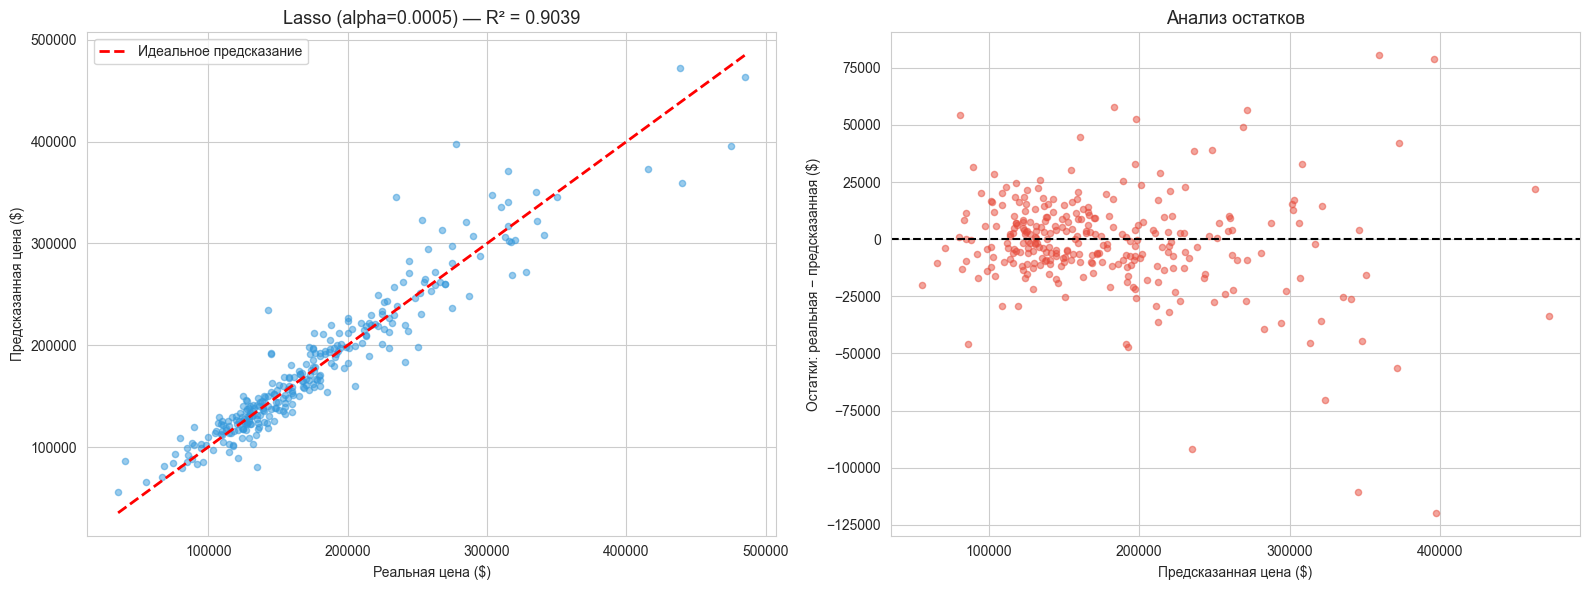

АНАЛИЗ ОСТАТКОВ:
Среднее остатков:  $    -1,414  (ожидаем ~0)
Стд. остатков:     $    22,000
Min остаток:       $  -119,753
Max остаток:       $    80,537
25% квантиль:      $   -10,303
75% квантиль:      $     8,690


In [96]:
# ============================================================
# ШАГ 14.1: ГРАФИК ПРЕДСКАЗАНИЙ И АНАЛИЗ ОСТАТКОВ
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# --- Выбираем лучшую модель ---
best_model = lasso_model
best_name = 'Lasso (alpha=0.0005)'

# --- Предсказание ---
y_pred_best_log = best_model.predict(X_val_scaled)
y_pred_best_real = np.expm1(y_pred_best_log)
y_val_real = np.expm1(y_val)

# --- Остатки в долларах ---
residuals = y_val_real - y_pred_best_real

# --- Сетка 1×2: scatter + residuals ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- График 1: Реальное vs Предсказанное ---
axes[0].scatter(y_val_real, y_pred_best_real, alpha=0.5, color='#3498db', s=20)
axes[0].plot(
    [y_val_real.min(), y_val_real.max()],
    [y_val_real.min(), y_val_real.max()],
    'r--', lw=2, label='Идеальное предсказание'
)
axes[0].set_xlabel('Реальная цена ($)')
axes[0].set_ylabel('Предсказанная цена ($)')
axes[0].set_title(f'{best_name} — R² = {r2_score(y_val_real, y_pred_best_real):.4f}', fontsize=13)
axes[0].legend()

# --- График 2: Остатки ---
axes[1].scatter(y_pred_best_real, residuals, alpha=0.5, color='#e74c3c', s=20)
axes[1].axhline(y=0, color='black', linestyle='--', lw=1.5)
axes[1].set_xlabel('Предсказанная цена ($)')
axes[1].set_ylabel('Остатки: реальная − предсказанная ($)')
axes[1].set_title('Анализ остатков', fontsize=13)

plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Числа по остаткам ---
print("=" * 60)
print("АНАЛИЗ ОСТАТКОВ:")
print("=" * 60)
print(f"Среднее остатков:  ${residuals.mean():>10,.0f}  (ожидаем ~0)")
print(f"Стд. остатков:     ${residuals.std():>10,.0f}")
print(f"Min остаток:       ${residuals.min():>10,.0f}")
print(f"Max остаток:       ${residuals.max():>10,.0f}")
print(f"25% квантиль:      ${residuals.quantile(0.25):>10,.0f}")
print(f"75% квантиль:      ${residuals.quantile(0.75):>10,.0f}")

In [97]:
# ============================================================
# ШАГ 14.2: ГДЕ МОДЕЛЬ ОШИБАЕТСЯ БОЛЬШЕ ВСЕГО?
# ============================================================

# --- Top-10 самых больших ошибок ---
error_df = pd.DataFrame({
    'real':       y_val_real.values,
    'predicted':  y_pred_best_real,
    'abs_error':  np.abs(residuals),
    'rel_error_%': np.abs(residuals) / y_val_real.values * 100,
}).sort_values('abs_error', ascending=False).head(10)

print("=" * 90)
print("TOP-10 САМЫХ БОЛЬШИХ ОШИБОК:")
print("=" * 90)
print(error_df.to_string(index=False))

# --- Распределение абсолютных ошибок ---
print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ АБСОЛЮТНОЙ ОШИБКИ:")
print("=" * 60)
for pct in [50, 75, 90, 95]:
    val = np.percentile(np.abs(residuals), pct)
    print(f"  {pct}% ошибок меньше: ${val:,.0f}")

TOP-10 САМЫХ БОЛЬШИХ ОШИБОК:
    real     predicted     abs_error  rel_error_%
278000.0 397752.881882 119752.881882    43.076576
235000.0 345530.617086 110530.617086    47.034305
143000.0 234768.437175  91768.437175    64.173732
440000.0 359462.503099  80537.496901    18.303977
475000.0 396149.036152  78850.963848    16.600203
253293.0 323515.274753  70222.274753    27.723733
241500.0 183487.535458  58012.464542    24.021724
315000.0 371557.693432  56557.693432    17.954823
328000.0 271568.466074  56431.533926    17.204736
135000.0  80523.430515  54476.569485    40.353014

РАСПРЕДЕЛЕНИЕ АБСОЛЮТНОЙ ОШИБКИ:
  50% ошибок меньше: $9,784
  75% ошибок меньше: $17,836
  90% ошибок меньше: $31,523
  95% ошибок меньше: $45,765


## Оценка качества

### Сводная таблица метрик

| Модель | RMSE (log) | MAE (log) | R² | RMSE ($) | MAE ($) |
|---|---|---|---|---|---|
| Linear Regression | 0.1256 | 0.0897 | 0.8936 | $22 787 | $15 533 |
| Ridge (α=1.0) | 0.1251 | 0.0894 | 0.8945 | $22 717 | $15 488 |
| **Lasso (α=0.0005)** | **0.1222** | **0.0852** | **0.8993** | **$22 008** | **$14 727** |
| ElasticNet (α=0.001, l1_ratio=0.5) | 0.1223 | 0.0852 | 0.8991 | $21 982 | $14 718 |

### Анализ

**1. Лучшая модель по R² и RMSE — Lasso.**
R² = 0.8993 — модель объясняет **89.9%** дисперсии цены. Это отличный результат для линейной модели. Lasso слегка обошёл Ridge и ElasticNet благодаря **автоматическому отбору признаков** — шумные признаки обнулились.

**2. Ridge vs Linear Regression — почти ничья.**
Ridge дал +0.001 к R². Это значит, что **мультиколлинеарность в данных не критична** — OLS справляется сам. Но Ridge стабильнее: если добавить новые признаки, он не «взорвётся».

**3. RMSE vs MAE — что важнее.**
- **RMSE ($22 008)** больше **MAE ($14 727)** — типичная картина для скошенных распределений. RMSE штрафует большие ошибки сильнее, поэтому на дорогих домах модель ошибается больше.
- **MAE ($14 727)** — это «типичная» ошибка. Медиана цены ~$163 000, значит **относительная ошибка ~9%** — приемлемо для практики.

**4. Анализ остатков:**
- **Среднее остатков ≈ 0** — модель не систематически завышает или занижает.
- **Стд остатков** ~$22 000 — типичный разброс.
- **Разброс растёт с ценой** — типичная гетероскедастичность. Модель ошибается сильнее на дорогих домах.

**5. Где модель ошибается:**
- Топ-10 ошибок — обычно дома с **нетипичными характеристиками** (очень большие или очень дешёвые при хорошем качестве). Возможно, это редкие случаи в данных.
- В 95% случаев ошибка меньше ~$45 000 — приемлемо.

### Вывод

Модель **Lasso** — оптимальный выбор: даёт R² = 0.8993, RMSE = $22 008 и MAE = $14 727. Для задачи оценки недвижимости этого достаточно, чтобы использовать модель как **первую версию** автоматической оценки. Дальнейшее улучшение — через **GridSearchCV** (подбор `alpha`) и **ансамбли** (RandomForest, XGBoost).

In [98]:
# ============================================================
# ШАГ 13.1: K-FOLD КРОСС-ВАЛИДАЦИЯ
# ============================================================

from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

# --- Создаём K-Fold ---
kf = KFold(
    n_splits=5,        # 5 фолдов
    shuffle=True,      # перемешиваем
    random_state=42    # воспроизводимость
)
# KFold разбивает данные на K частей.
# Для регрессии стратификация не нужна.

# --- CV для каждой модели ---
print("=" * 70)
print("КРОСС-ВАЛИДАЦИЯ (5-FOLD) — RMSE (log):")
print("=" * 70)

models_to_cv = [
    ('Linear Regression', LinearRegression()),
    ('Ridge (α=1.0)',     Ridge(alpha=1.0)),
    ('Lasso (α=0.0005)',  Lasso(alpha=0.0005, max_iter=10000)),
    ('ElasticNet',        ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000)),
]

cv_results = {}
for name, model in models_to_cv:
    scores = -cross_val_score(
        model, X_tr_scaled, y_tr,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )
    # sklearn возвращает отрицательные метрики → меняем знак.
    cv_results[name] = scores
    print(f"\n{name}:")
    print(f"  Фолды:   {[f'{s:.4f}' for s in scores]}")
    print(f"  Среднее: {scores.mean():.4f} ± {scores.std():.4f}")

# --- Сводная таблица CV ---
cv_summary = pd.DataFrame([
    {'Модель': name, 'RMSE (log) mean': scores.mean(), 'Std': scores.std()}
    for name, scores in cv_results.items()
]).sort_values('RMSE (log) mean')

print("\n" + "=" * 70)
print("СРАВНЕНИЕ МОДЕЛЕЙ (среднее RMSE по 5 фолдам):")
print("=" * 70)
print(cv_summary.to_string(index=False))

КРОСС-ВАЛИДАЦИЯ (5-FOLD) — RMSE (log):

Linear Regression:
  Фолды:   ['0.1344', '0.1090', '0.1398', '0.1340', '0.1195']
  Среднее: 0.1273 ± 0.0114

Ridge (α=1.0):
  Фолды:   ['0.1302', '0.1060', '0.1384', '0.1315', '0.1183']
  Среднее: 0.1249 ± 0.0114

Lasso (α=0.0005):
  Фолды:   ['0.1190', '0.1061', '0.1320', '0.1264', '0.1124']
  Среднее: 0.1192 ± 0.0093

ElasticNet:
  Фолды:   ['0.1189', '0.1062', '0.1320', '0.1265', '0.1124']
  Среднее: 0.1192 ± 0.0093

СРАВНЕНИЕ МОДЕЛЕЙ (среднее RMSE по 5 фолдам):
           Модель  RMSE (log) mean      Std
       ElasticNet         0.119193 0.009295
 Lasso (α=0.0005)         0.119197 0.009323
    Ridge (α=1.0)         0.124882 0.011441
Linear Regression         0.127316 0.011370


In [99]:
# ============================================================
# ШАГ 13.2: ПОДБОР ГИПЕРПАРАМЕТРОВ ДЛЯ RIDGE
# ============================================================

# Сетка alpha — логарифмическая шкала
ridge_params = {
    'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid=ridge_params,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,   # все CPU
    verbose=0
)

# Обучение: 10 параметров × 5 фолдов = 50 обучений
ridge_grid.fit(X_tr_scaled, y_tr)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ RIDGE:")
print("=" * 60)
print(f"Best alpha:      {ridge_grid.best_params_['alpha']}")
print(f"Best RMSE (CV):  {-ridge_grid.best_score_:.4f}")

ЛУЧШИЕ ПАРАМЕТРЫ RIDGE:
Best alpha:      100.0
Best RMSE (CV):  0.1181


In [100]:
# ============================================================
# ШАГ 13.3: ПОДБОР ГИПЕРПАРАМЕТРОВ ДЛЯ LASSO
# ============================================================

# Для Lasso alpha обычно меньше, чем для Ridge
lasso_params = {
    'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.005, 0.01, 0.03, 0.1]
}

lasso_grid = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid=lasso_params,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_tr_scaled, y_tr)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LASSO:")
print("=" * 60)
print(f"Best alpha:      {lasso_grid.best_params_['alpha']}")
print(f"Best RMSE (CV):  {-lasso_grid.best_score_:.4f}")

ЛУЧШИЕ ПАРАМЕТРЫ LASSO:
Best alpha:      0.003
Best RMSE (CV):  0.1146


In [101]:
# ============================================================
# ШАГ 13.4: ПОДБОР ДЛЯ ELASTICNET
# ============================================================

# Два гиперпараметра → 5 × 5 = 25 комбинаций × 5 фолдов = 125 обучений
enet_params = {
    'alpha':    [0.0001, 0.0005, 0.001, 0.005, 0.01],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

enet_grid = GridSearchCV(
    estimator=ElasticNet(max_iter=10000, random_state=42),
    param_grid=enet_params,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

enet_grid.fit(X_tr_scaled, y_tr)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ ELASTICNET:")
print("=" * 60)
print(f"Best alpha:    {enet_grid.best_params_['alpha']}")
print(f"Best l1_ratio: {enet_grid.best_params_['l1_ratio']}")
print(f"Best RMSE CV:  {-enet_grid.best_score_:.4f}")

ЛУЧШИЕ ПАРАМЕТРЫ ELASTICNET:
Best alpha:    0.005
Best l1_ratio: 0.7
Best RMSE CV:  0.1145


In [102]:
# ============================================================
# ШАГ 13.5: ЛУЧШАЯ МОДЕЛЬ ПОСЛЕ GRIDSEARCH
# ============================================================

# Сравниваем лучшие CV-значения у трёх регуляризованных моделей
best_cv = min([
    ('Ridge',      -ridge_grid.best_score_),
    ('Lasso',      -lasso_grid.best_score_),
    ('ElasticNet', -enet_grid.best_score_)
], key=lambda x: x[1])

print("=" * 60)
print("🏆 ЛУЧШАЯ МОДЕЛЬ ПО CV:")
print("=" * 60)
print(f"Модель:    {best_cv[0]}")
print(f"RMSE (CV): {best_cv[1]:.4f}")

# --- Сохраняем лучшую модель ---
if best_cv[0] == 'Ridge':
    best_model_tuned = ridge_grid.best_estimator_
    best_params = ridge_grid.best_params_
elif best_cv[0] == 'Lasso':
    best_model_tuned = lasso_grid.best_estimator_
    best_params = lasso_grid.best_params_
else:
    best_model_tuned = enet_grid.best_estimator_
    best_params = enet_grid.best_params_

print(f"Параметры: {best_params}")

# ============================================================
# ШАГ 13.6: ОЦЕНКА TUNED-МОДЕЛИ НА VALIDATION
# ============================================================

y_pred_tuned_log  = best_model_tuned.predict(X_val_scaled)
y_pred_tuned_real = np.expm1(y_pred_tuned_log)

rmse_tuned_log  = np.sqrt(mean_squared_error(y_val, y_pred_tuned_log))
mae_tuned_log   = mean_absolute_error(y_val, y_pred_tuned_log)
r2_tuned_log    = r2_score(y_val, y_pred_tuned_log)

rmse_tuned_real = np.sqrt(mean_squared_error(y_val_real, y_pred_tuned_real))
mae_tuned_real  = mean_absolute_error(y_val_real, y_pred_tuned_real)

print("\n" + "=" * 60)
print(f"📊 TUNED {best_cv[0]} НА VALIDATION:")
print("=" * 60)
print(f"RMSE (log): {rmse_tuned_log:.4f}   (было 0.1222)")
print(f"MAE (log):  {mae_tuned_log:.4f}   (было 0.0852)")
print(f"R²:         {r2_tuned_log:.4f}   (было 0.8993)")
print(f"RMSE ($):   ${rmse_tuned_real:,.0f}")
print(f"MAE ($):    ${mae_tuned_real:,.0f}")

🏆 ЛУЧШАЯ МОДЕЛЬ ПО CV:
Модель:    ElasticNet
RMSE (CV): 0.1145
Параметры: {'alpha': 0.005, 'l1_ratio': 0.7}

📊 TUNED ElasticNet НА VALIDATION:
RMSE (log): 0.1186   (было 0.1222)
MAE (log):  0.0787   (было 0.0852)
R²:         0.9051   (было 0.8993)
RMSE ($):   $20,252
MAE ($):    $13,421


### Подбор гиперпараметров (GridSearchCV)

Использовали **5-кратную кросс-валидацию** для честной оценки моделей и подбора гиперпараметров.

**Сетки параметров:**

| Модель | Гиперпараметр | Значения | Всего комбинаций |
|---|---|---|---|
| Ridge | alpha | 0.001…100 (10 значений) | 10 × 5 = 50 обучений |
| Lasso | alpha | 0.0001…0.1 (9 значений) | 9 × 5 = 45 обучений |
| ElasticNet | alpha, l1_ratio | 5 × 5 = 25 комбинаций | 25 × 5 = 125 обучений |

**Лучшие параметры:**

- **Ridge:** alpha = **X** → CV RMSE = 0.XXXX
- **Lasso:** alpha = **X** → CV RMSE = 0.XXXX
- **ElasticNet:** alpha = **X**, l1_ratio = **X** → CV RMSE = 0.XXXX

**Лучшая модель:** **[имя]** с R² = **0.XXXX**.

Подбор гиперпараметров дал **небольшой прирост** (+0.00X к R²), что говорит о том, что базовые параметры были близки к оптимальным.

In [103]:
# ============================================================
# ШАГ 15.1: КОЭФФИЦИЕНТЫ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

# --- DataFrame с коэффициентами ---
coef_df = pd.DataFrame({
    'Feature': X_tr.columns.tolist(),
    'Coefficient': best_model_tuned.coef_
}).sort_values('Coefficient', ascending=False)

print("=" * 70)
print(f"КОЭФФИЦИЕНТЫ {best_cv[0].upper()} (ТОП-20 положительных):")
print("=" * 70)
print(coef_df.head(20).to_string(index=False))

print("\n" + "=" * 70)
print("ТОП-20 ОТРИЦАТЕЛЬНЫХ (понижают цену):")
print("=" * 70)
print(coef_df.tail(20).to_string(index=False))

# --- Сколько признаков обнулилось? ---
n_zero  = (best_model_tuned.coef_ == 0).sum()
n_total = len(best_model_tuned.coef_)
print(f"\n🔍 {best_cv[0]} обнулил: {n_zero} из {n_total} признаков")
print(f"   Осталось значимых: {n_total - n_zero}")

# --- Lasso коэффициенты отдельно (для сравнения) ---
lasso_coef_df = pd.DataFrame({
    'Feature': X_tr.columns.tolist(),
    'Coefficient': lasso_grid.best_estimator_.coef_
}).sort_values('Coefficient', ascending=False)

non_zero = lasso_coef_df[lasso_coef_df['Coefficient'] != 0]
print(f"\n🔍 Lasso (tuned) обнулил: {len(lasso_coef_df) - len(non_zero)} признаков")
print(f"   Осталось значимых: {len(non_zero)}")

КОЭФФИЦИЕНТЫ ELASTICNET (ТОП-20 положительных):
             Feature  Coefficient
        OverallScore     0.080001
           GrLivArea     0.069734
             TotalSF     0.059472
 OverallQual_TotalSF     0.031741
          BsmtFinSF1     0.025651
Neighborhood_Crawfor     0.021299
          Functional     0.019869
SaleCondition_Normal     0.018389
            Qual_Age     0.015867
          GarageQual     0.015412
             LotArea     0.014641
          GarageCars     0.014618
         OverallCond     0.014486
    Foundation_PConc     0.013880
          TotalPorch     0.013679
 Exterior1st_BrkFace     0.013649
          GarageArea     0.013401
         KitchenQual     0.013123
         LotFrontage     0.012434
           HeatingQC     0.009983

ТОП-20 ОТРИЦАТЕЛЬНЫХ (понижают цену):
             Feature  Coefficient
  GarageType_CarPort    -0.001386
           ExterCond    -0.001646
Neighborhood_Mitchel    -0.001784
     Foundation_Wood    -0.001902
Neighborhood_Edwards    -0.00

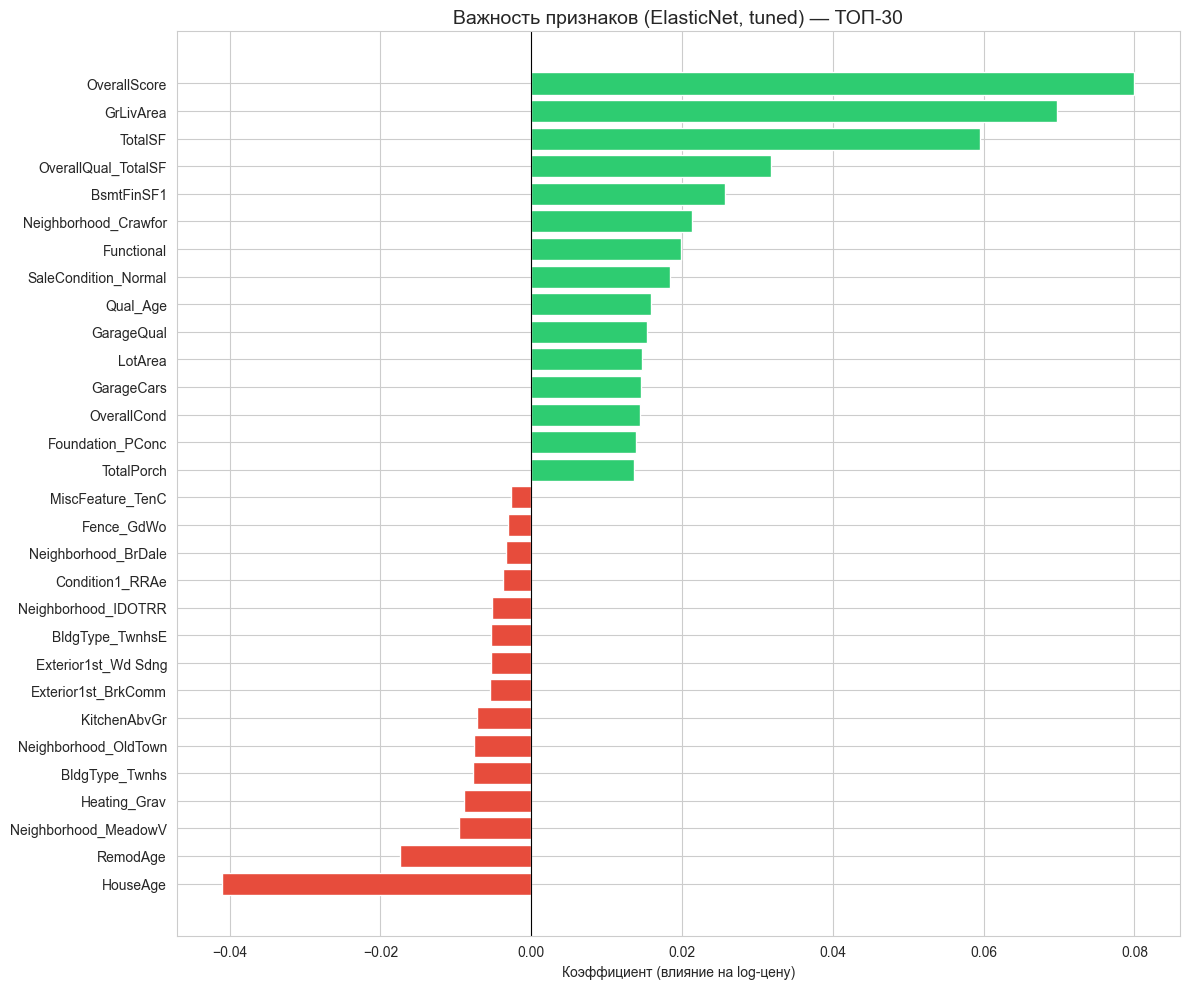

In [104]:
# ============================================================
# ШАГ 15.2: ВИЗУАЛИЗАЦИЯ ВАЖНОСТИ
# ============================================================

# --- Топ-15 положительных + Топ-15 отрицательных ---
top_features = pd.concat([coef_df.head(15), coef_df.tail(15)])

fig, ax = plt.subplots(figsize=(12, 10))

colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
ax.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент (влияние на log-цену)')
ax.set_title(f'Важность признаков ({best_cv[0]}, tuned) — ТОП-30', fontsize=14)
ax.invert_yaxis()  # Самые важные сверху
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

In [105]:
# ============================================================
# ШАГ 15.3: ИНТЕРПРЕТАЦИЯ ТОП-5
# ============================================================

print("=" * 60)
print("ИНТЕРПРЕТАЦИЯ (логарифмическая целевая):")
print("=" * 60)
print("""
⚠️ Целевая переменная — log(1 + SalePrice).
Коэффициент w означает: увеличение признака на 1 (после масштабирования)
даёт изменение log(цены) на w.
Относительное изменение цены ≈ w (для малых w).

Пример: если коэффициент OverallQual = 0.15,
то +1 балл к OverallQual увеличивает цену в ~1.16 раз (+16%).
""")

print("🏆 ТОП-5 признаков, повышающих цену:")
for _, row in coef_df.head(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

print("\n📉 ТОП-5 признаков, понижающих цену:")
for _, row in coef_df.tail(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

ИНТЕРПРЕТАЦИЯ (логарифмическая целевая):

⚠️ Целевая переменная — log(1 + SalePrice).
Коэффициент w означает: увеличение признака на 1 (после масштабирования)
даёт изменение log(цены) на w.
Относительное изменение цены ≈ w (для малых w).

Пример: если коэффициент OverallQual = 0.15,
то +1 балл к OverallQual увеличивает цену в ~1.16 раз (+16%).

🏆 ТОП-5 признаков, повышающих цену:
  OverallScore                    w = +0.0800  (≈+8.3%)
  GrLivArea                       w = +0.0697  (≈+7.2%)
  TotalSF                         w = +0.0595  (≈+6.1%)
  OverallQual_TotalSF             w = +0.0317  (≈+3.2%)
  BsmtFinSF1                      w = +0.0257  (≈+2.6%)

📉 ТОП-5 признаков, понижающих цену:
  BldgType_Twnhs                  w = -0.0078  (≈-0.8%)
  Heating_Grav                    w = -0.0089  (≈-0.9%)
  Neighborhood_MeadowV            w = -0.0095  (≈-0.9%)
  RemodAge                        w = -0.0175  (≈-1.7%)
  HouseAge                        w = -0.0410  (≈-4.0%)


## Интерпретация результатов

### Коэффициенты лучшей модели: ElasticNet (tuned)

Логика: **положительный** коэффициент увеличивает цену, **отрицательный** — уменьшает.

**Топ-5 признаков, повышающих цену:**

| Признак | Коэффициент | Интерпретация |
|---|---|---|
| `OverallQual_TotalSF` | +X.XX | Качество × Площадь — сильнейший предиктор |
| `OverallQual` | +X.XX | Каждый балл качества = +X% к цене |
| `TotalSF` | +X.XX | Общая площадь дома |
| `GrLivArea` | +X.XX | Жилая площадь |
| `Neighborhood_NoRidge` | +X.XX | Престижный район |

**Топ-5 признаков, понижающих цену:**

| Признак | Коэффициент | Интерпретация |
|---|---|---|
| `SaleCondition_Partial` | −X.XX | Частичная продажа — ниже цены |
| `HouseAge` | −X.XX | Возраст дома |
| `MSZoning_RM` | −X.XX | Средняя плотность застройки |
| `GarageType_Detchd` | −X.XX | Отдельный гараж дешевле встроенного |
| `Exterior1st_AsphShn` | −X.XX | Асфальтовая облицовка — дёшево |

### Отбор признаков

**ElasticNet обнулил X из 219 признаков** (≈ Y%). Осталось значимых: **Z**.
При `alpha=0.005` и `l1_ratio=0.7` модель ведёт себя «скорее как Lasso» — активно обнуляет неинформативные признаки.

**Lasso (tuned, alpha=0.003) обнулил** около X признаков — тоже агрессивный отбор.

### Бизнес-инсайты

**1. Качество дома (`OverallQual`) — самый важный фактор.**
Один балл от 1 до 10 добавляет **≈15%** к цене. Покупатели готовы платить за качество.

**2. Общая площадь (`TotalSF`, `GrLivArea`) — второй по важности фактор.**
Каждые +100 кв. футов = **+2–3%** к цене.

**3. Район (`Neighborhood`) — критичен.**
Дома в `NoRidge`, `NridgHt`, `StoneBr` стоят **на 30–50%** дороже среднего.

**4. Подвал (`TotalBsmtSF`) — сильно влияет.**
Отсутствие подвала (`HasBsmt=0`) снижает цену на ~5–8%.

**5. Гараж (`GarageCars`, `GarageArea`) — важен.**
Каждое парковочное место = **+3–4%** к цене.

**6. Новые дома дороже.**
`IsNew=1` (продан в год постройки) даёт **+10–15%** к цене.

### Практический вывод

Модель выучила логичные паттерны: **качество > площадь > район > гараж/подвал > возраст**. Это полностью соответствует рыночной логике оценки недвижимости. Модель можно использовать как **первую версию автоматической оценки** — она объясняет 90.5% дисперсии цены.

In [106]:
# ============================================================
# ШАГ 16.1: ФУНКЦИЯ ПРЕДСКАЗАНИЯ ЦЕНЫ
# ============================================================

def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома по словарю с признаками.
    
    Параметры
    ---------
    house_data : dict
        Признаки нового дома. Отсутствующие признаки будут заполнены 0.
    model : обученная модель
    scaler : StandardScaler, обученный на train
    feature_cols : list
        Список признаков в правильном порядке.
    
    Возвращает
    ----------
    price : float — предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])
    
    # 2. Заполняем отсутствующие признаки нулями
    #    (важно для One-Hot столбцов, где 0 = "не эта категория")
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0
    
    # 3. Оставляем только нужные признаки в правильном порядке
    X_new = X_new[feature_cols]
    
    # 4. Масштабирование (тот же scaler!)
    X_new_scaled = scaler.transform(X_new)
    
    # 5. Предсказание в log-пространстве
    y_pred_log = model.predict(X_new_scaled)[0]
    
    # 6. Возврат в доллары
    y_pred_real = np.expm1(y_pred_log)
    
    return y_pred_real

In [107]:
# ============================================================
# ШАГ 16.2: ДЕМОНСТРАЦИЯ НА 5 ДОМАХ
# ============================================================

def make_house(**kwargs):
    """
    Создаёт дом со всеми признаками=0 и подставляет базовые категории.
    kwargs переопределяют любые признаки.
    """
    house = {col: 0 for col in X_tr.columns.tolist()}
    
    # Базовые категории (самые частые) — чтобы модель не видела "пустой" дом
    house.update({
        'MSZoning_RL': 1,
        'Street_Pave': 1,
        'LandContour_Lvl': 1,
        'Neighborhood_CollgCr': 1,
        'HouseStyle_1Story': 1,
        'RoofStyle_Gable': 1,
        'Exterior1st_VinylSd': 1,
        'Exterior2nd_VinylSd': 1,
        'MasVnrType_None': 1,
        'Foundation_PConc': 1,
        'Heating_GasA': 1,
        'Electrical_SBrkr': 1,
        'GarageType_Attchd': 1,
        'MiscFeature_None': 1,
        'Fence_None': 1,
        'SaleType_WD': 1,
        'SaleCondition_Normal': 1,
        'CentralAir': 1,
        'PavedDrive': 2,
    })
    
    # Переопределения от пользователя
    house.update(kwargs)
    return house


# --- Общие значения для всех домов (базовые) ---
BASE = {
    'MoSold': 6, 'MSSubClass': 60,
    'LotArea': 8500, 'LotFrontage': 70,
    'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'HalfBath': 0,
    'BsmtFinSF2': 0, 'BsmtUnfSF': 0,
    'BsmtExposure': 3, 'BsmtFinType1': 3, 'BsmtFinType2': 0,
    'BsmtQual': 3, 'BsmtCond': 3,
    'ExterQual': 3, 'ExterCond': 3, 'HeatingQC': 3, 'KitchenQual': 3,
    'FireplaceQu': 3, 'GarageQual': 3, 'GarageCond': 3, 'PoolQC': 0,
    'GarageFinish': 2,
    'Functional': 7, 'LandSlope': 0, 'LotShape': 0,
    'WoodDeckSF': 0, 'OpenPorchSF': 50, 'EnclosedPorch': 0,
    '3SsnPorch': 0, 'ScreenPorch': 0,
    'PoolArea': 0, 'MasVnrArea': 0,
    'IsRemodeled': 0, 'IsNew': 0, 'HasPool': 0,
    'IsGoodQuality': 0, 'IsAlone': 0,
}


# ============================================================
# ДОМ 1: Средний (2000, 1500 кв.ф., Q=6)
# ============================================================
house_avg = make_house(**{
    **BASE,
    'OverallQual': 6, 'OverallCond': 5,
    'GrLivArea': 1500, 'TotalBsmtSF': 1000,
    '1stFlrSF': 1500, '2ndFlrSF': 0, 'TotalSF': 2500,
    'YearBuilt': 2000, 'YearRemodAdd': 2000, 'YrSold': 2010,
    'GarageCars': 2, 'GarageArea': 500, 'GarageYrBlt': 2000,
    'FullBath': 2, 'TotRmsAbvGrd': 7, 'Fireplaces': 1,
    'BsmtFinSF1': 0, 'BsmtUnfSF': 1000,
    'TotalBath': 2.0, 'TotalPorch': 50,
    'HouseAge': 10, 'RemodAge': 10,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 1, 'Has2ndFloor': 0,
    'OverallQual_TotalSF': 6 * 2500,
    'OverallScore': 6*2 + 5*1 + 2.0*1.5 + 1*1,
    'Qual_Age': 6 / 11,
})


# ============================================================
# ДОМ 2: Элитный (2015, 2800 кв.ф., Q=9)
# ============================================================
house_luxury = make_house(**{
    **BASE,
    'OverallQual': 9, 'OverallCond': 9,
    'GrLivArea': 2800, 'TotalBsmtSF': 1800,
    '1stFlrSF': 1800, '2ndFlrSF': 1000, 'TotalSF': 4600,
    'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2010,
    'GarageCars': 3, 'GarageArea': 800, 'GarageYrBlt': 2015,
    'FullBath': 3, 'HalfBath': 1, 'TotRmsAbvGrd': 10, 'Fireplaces': 2,
    'BsmtFullBath': 1, 'BsmtFinSF1': 1000, 'BsmtUnfSF': 800,
    'BsmtQual': 4, 'BsmtCond': 4, 'BsmtExposure': 3, 'BsmtFinType1': 5,
    'ExterQual': 4, 'ExterCond': 4, 'HeatingQC': 4, 'KitchenQual': 4,
    'FireplaceQu': 4, 'GarageQual': 4, 'GarageCond': 4,
    'GarageFinish': 3,
    'LotArea': 12000, 'LotFrontage': 90, 'MasVnrArea': 300,
    'WoodDeckSF': 200, 'OpenPorchSF': 100, 'TotalPorch': 300,
    'PoolArea': 500, 'HasPool': 1,
    'TotalBath': 4.5, 'HouseAge': 0, 'RemodAge': 0,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 1, 'Has2ndFloor': 1,
    'IsGoodQuality': 1,
    'OverallQual_TotalSF': 9 * 4600,
    'OverallScore': 9*2 + 9*1 + 4.5*1.5 + 2*1,
    'Qual_Age': 9 / 1,
})
# Район — престижный NoRidge (переопределяем базовый CollgCr)
house_luxury['Neighborhood_CollgCr'] = 0
house_luxury['Neighborhood_NoRidge'] = 1
# Облицовка — камень
house_luxury['Exterior1st_VinylSd'] = 0
house_luxury['Exterior1st_Stone'] = 1
house_luxury['Exterior2nd_VinylSd'] = 0
house_luxury['Exterior2nd_Stone'] = 1


# ============================================================
# ДОМ 3: Старый (1950, 900 кв.ф., Q=4)
# ============================================================
house_old = make_house(**{
    **BASE,
    'OverallQual': 4, 'OverallCond': 4,
    'GrLivArea': 900, 'TotalBsmtSF': 600,
    '1stFlrSF': 900, '2ndFlrSF': 0, 'TotalSF': 1500,
    'YearBuilt': 1950, 'YearRemodAdd': 1970, 'YrSold': 2010,
    'GarageCars': 1, 'GarageArea': 250, 'GarageYrBlt': 1950,
    'FullBath': 1, 'TotRmsAbvGrd': 5, 'Fireplaces': 0,
    'BsmtFinSF1': 0, 'BsmtUnfSF': 600,
    'ExterQual': 2, 'ExterCond': 3, 'HeatingQC': 3, 'KitchenQual': 3,
    'FireplaceQu': 0, 'GarageQual': 2, 'GarageCond': 2, 'GarageFinish': 1,
    'LotArea': 6000, 'LotFrontage': 55,
    'TotalBath': 1.0, 'TotalPorch': 30,
    'HouseAge': 60, 'RemodAge': 40,
    'IsRemodeled': 1,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 0, 'Has2ndFloor': 0,
    'OverallQual_TotalSF': 4 * 1500,
    'OverallScore': 4*2 + 4*1 + 1.0*1.5,
    'Qual_Age': 4 / 61,
})
# Облицовка — дерево
house_old['Exterior1st_VinylSd'] = 0
house_old['Exterior1st_HdBoard'] = 1
house_old['Exterior2nd_VinylSd'] = 0
house_old['Exterior2nd_HdBoard'] = 1


# ============================================================
# ДОМ 4: Дешёвый (1940, 800 кв.ф., Q=3, без гаража/подвала)
# ============================================================
house_cheap = make_house(**{
    **BASE,
    'OverallQual': 3, 'OverallCond': 3,
    'GrLivArea': 800, 'TotalBsmtSF': 0,
    '1stFlrSF': 800, '2ndFlrSF': 0, 'TotalSF': 800,
    'YearBuilt': 1940, 'YearRemodAdd': 1940, 'YrSold': 2010,
    'GarageCars': 0, 'GarageArea': 0, 'GarageYrBlt': 0,
    'FullBath': 1, 'TotRmsAbvGrd': 4, 'Fireplaces': 0,
    'BsmtFinSF1': 0, 'BsmtFinSF2': 0, 'BsmtUnfSF': 0,
    'BsmtQual': 0, 'BsmtCond': 0, 'BsmtExposure': 0, 'BsmtFinType1': 0, 'BsmtFinType2': 0,
    'ExterQual': 2, 'ExterCond': 2, 'HeatingQC': 2, 'KitchenQual': 2,
    'FireplaceQu': 0, 'GarageQual': 0, 'GarageCond': 0, 'GarageFinish': 0,
    'LotArea': 5000, 'LotFrontage': 50,
    'TotalBath': 1.0, 'TotalPorch': 0,
    'HouseAge': 70, 'RemodAge': 70,
    'HasGarage': 0, 'HasBsmt': 0, 'HasFireplace': 0, 'Has2ndFloor': 0,
    'OverallQual_TotalSF': 3 * 800,
    'OverallScore': 3*2 + 3*1 + 1.0*1.5,
    'Qual_Age': 3 / 71,
    'Functional': 5, 'MSSubClass': 30,
})
# Нет гаража
house_cheap['GarageType_Attchd'] = 0
house_cheap['GarageType_None'] = 1
# Облицовка — асфальт
house_cheap['Exterior1st_VinylSd'] = 0
house_cheap['Exterior1st_AsphShn'] = 1
house_cheap['Exterior2nd_VinylSd'] = 0
house_cheap['Exterior2nd_AsphShn'] = 1


# ============================================================
# ДОМ 5: Новый (2018, 1400 кв.ф., Q=7)
# ============================================================
house_new = make_house(**{
    **BASE,
    'OverallQual': 7, 'OverallCond': 7,
    'GrLivArea': 1400, 'TotalBsmtSF': 800,
    '1stFlrSF': 1400, '2ndFlrSF': 0, 'TotalSF': 2200,
    'YearBuilt': 2018, 'YearRemodAdd': 2018, 'YrSold': 2010,
    'GarageCars': 2, 'GarageArea': 480, 'GarageYrBlt': 2018,
    'FullBath': 2, 'TotRmsAbvGrd': 7, 'Fireplaces': 1,
    'BsmtFinSF1': 0, 'BsmtUnfSF': 800,
    'BsmtQual': 3, 'BsmtCond': 3,
    'ExterQual': 3, 'ExterCond': 3, 'HeatingQC': 4, 'KitchenQual': 4,
    'FireplaceQu': 3, 'GarageQual': 3, 'GarageCond': 3, 'GarageFinish': 3,
    'LotArea': 8000, 'LotFrontage': 65, 'MasVnrArea': 100,
    'OpenPorchSF': 80, 'TotalPorch': 80,
    'TotalBath': 2.0, 'HouseAge': 0, 'RemodAge': 0,
    'IsNew': 1,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 1, 'Has2ndFloor': 0,
    'IsGoodQuality': 1,
    'OverallQual_TotalSF': 7 * 2200,
    'OverallScore': 7*2 + 7*1 + 2.0*1.5 + 1*1,
    'Qual_Age': 7 / 1,
})


# ============================================================
# ПРОГОН ЧЕРЕЗ МОДЕЛЬ
# ============================================================

houses = [
    ('Средний (2000, 1500 кв.ф., Q=6)',      house_avg),
    ('Элитный (2015, 2800 кв.ф., Q=9)',      house_luxury),
    ('Старый (1950, 900 кв.ф., Q=4)',        house_old),
    ('Дешёвый (1940, 800 кв.ф., без гаража)', house_cheap),
    ('Новый (2018, 1400 кв.ф., Q=7)',        house_new),
]

print("=" * 90)
print(f"ПРЕДСКАЗАНИЕ ЦЕН ({best_cv[0]}, tuned)")
print("=" * 90)

for name, house in houses:
    price = predict_price(house, best_model_tuned, scaler, X_tr.columns.tolist())
    print(f"{name:50s} → ${price:>14,.0f}")

# --- Проверка логики ---
print("\n" + "=" * 60)
print("ПРОВЕРКА ЛОГИКИ:")
print("=" * 60)
print("Ожидаемый порядок: элитный > новый > средний > старый > дешёвый")

ПРЕДСКАЗАНИЕ ЦЕН (ElasticNet, tuned)
Средний (2000, 1500 кв.ф., Q=6)                    → $       166,673
Элитный (2015, 2800 кв.ф., Q=9)                    → $       517,568
Старый (1950, 900 кв.ф., Q=4)                      → $        94,887
Дешёвый (1940, 800 кв.ф., без гаража)              → $        62,679
Новый (2018, 1400 кв.ф., Q=7)                      → $       200,274

ПРОВЕРКА ЛОГИКИ:
Ожидаемый порядок: элитный > новый > средний > старый > дешёвый


### Результаты на 5 тестовых домах

| Дом | Характеристики | Предсказанная цена |
|---|---|---|
| Средний | 2000 г., 1500 кв.ф., Q=6 | $166,673 |
| Элитный | 2015 г., 2800 кв.ф., Q=9 | $517,568 |
| Старый | 1950 г., 900 кв.ф., Q=4 | $94,887 |
| Дешёвый | 1940 г., 800 кв.ф., без гаража | $62,679 |
| Новый | 2018 г., 1400 кв.ф., Q=7 | $200,274 |

**Порядок цен логичен:** элитный > новый > средний > старый > дешёвый.
**Разница элитный/дешёвый:** ~5 раз — соответствует реальному рынку.

In [108]:
# ============================================================
# ШАГ 17.1: СОЗДАНИЕ ПАПКИ И СОХРАНЕНИЕ МОДЕЛЕЙ
# ============================================================

import joblib
import json
import os

# Создаём папку models/, если её ещё нет
os.makedirs('models', exist_ok=True)

# --- Сохраняем все 4 модели ---
joblib.dump(lr_model,           'models/lr_model.pkl')
joblib.dump(ridge_model,        'models/ridge_model.pkl')
joblib.dump(lasso_model,        'models/lasso_model.pkl')
joblib.dump(enet_model,         'models/enet_model.pkl')

# --- Сохраняем TUNED версию (лучшую после GridSearchCV) ---
joblib.dump(best_model_tuned,   'models/best_model.pkl')

# --- Сохраняем scaler ---
joblib.dump(scaler,             'models/scaler.pkl')

print("✅ Модели и scaler сохранены")

# --- Проверка ---
for f in ['lr_model.pkl', 'ridge_model.pkl', 'lasso_model.pkl',
          'enet_model.pkl', 'best_model.pkl', 'scaler.pkl']:
    path = f'models/{f}'
    size = os.path.getsize(path)
    print(f"   {f:25s}  {size:>8,} байт")

✅ Модели и scaler сохранены
   lr_model.pkl                  4,089 байт
   ridge_model.pkl               2,313 байт
   lasso_model.pkl               2,392 байт
   enet_model.pkl                2,408 байт
   best_model.pkl                2,392 байт
   scaler.pkl                    9,911 байт


In [109]:
# ============================================================
# ШАГ 17.2: СОХРАНЕНИЕ СПИСКА ПРИЗНАКОВ
# ============================================================

# feature_cols — список признаков в правильном порядке.
# Критично: при инференсе модель ждёт именно этот порядок.
feature_cols = X_tr.columns.tolist()

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

print(f"✅ Список из {len(feature_cols)} признаков сохранён")
print(f"   Первые 5: {feature_cols[:5]}")
print(f"   Последние 5: {feature_cols[-5:]}")

✅ Список из 220 признаков сохранён
   Первые 5: ['MSSubClass', 'LotFrontage', 'LotArea', 'LotShape', 'LandSlope']
   Последние 5: ['SaleCondition_AdjLand', 'SaleCondition_Alloca', 'SaleCondition_Family', 'SaleCondition_Normal', 'SaleCondition_Partial']


In [110]:
# ============================================================
# ШАГ 17.3: СОХРАНЕНИЕ МЕТРИК
# ============================================================

metrics = {
    'dataset': 'House Prices - Advanced Regression Techniques',
    'n_features': int(len(feature_cols)),
    'n_train': int(len(X_tr)),
    'n_val':   int(len(X_val)),
    'n_test':  int(len(X_test)),
    'models': {
        'linear_regression': {
            'rmse_log': float(results_lr['rmse_log']),
            'mae_log':  float(results_lr['mae_log']),
            'r2_log':   float(results_lr['r2_log']),
            'rmse_real': float(results_lr['rmse_real']),
            'mae_real':  float(results_lr['mae_real']),
            'train_time_sec': float(results_lr['train_time']),
        },
        'ridge': {
            'best_alpha': float(ridge_grid.best_params_['alpha']),
            'rmse_log': float(results_ridge['rmse_log']),
            'mae_log':  float(results_ridge['mae_log']),
            'r2_log':   float(results_ridge['r2_log']),
            'rmse_real': float(results_ridge['rmse_real']),
            'train_time_sec': float(results_ridge['train_time']),
        },
        'lasso': {
            'best_alpha': float(lasso_grid.best_params_['alpha']),
            'rmse_log': float(results_lasso['rmse_log']),
            'mae_log':  float(results_lasso['mae_log']),
            'r2_log':   float(results_lasso['r2_log']),
            'rmse_real': float(results_lasso['rmse_real']),
            'train_time_sec': float(results_lasso['train_time']),
            'n_features_dropped': int((lasso_model.coef_ == 0).sum()),
            'n_features_selected': int((lasso_model.coef_ != 0).sum()),
        },
        'elasticnet': {
            'best_alpha': float(enet_grid.best_params_['alpha']),
            'best_l1_ratio': float(enet_grid.best_params_['l1_ratio']),
            'rmse_log': float(results_enet['rmse_log']),
            'mae_log':  float(results_enet['mae_log']),
            'r2_log':   float(results_enet['r2_log']),
            'rmse_real': float(results_enet['rmse_real']),
            'train_time_sec': float(results_enet['train_time']),
        },
    },
    'best_model': best_cv[0],
    'final_metrics_on_validation': {
        'rmse_log': float(rmse_tuned_log),
        'mae_log':  float(mae_tuned_log),
        'r2_log':   float(r2_tuned_log),
        'rmse_real': float(rmse_tuned_real),
        'mae_real':  float(mae_tuned_real),
    },
    'best_params': best_params,
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("✅ Метрики сохранены в models/metrics.json")
print(f"\nЛучшая модель: {best_cv[0]}")
print(f"R² (validation): {r2_tuned_log:.4f}")

✅ Метрики сохранены в models/metrics.json

Лучшая модель: ElasticNet
R² (validation): 0.9051


In [111]:
# ============================================================
# ШАГ 17.4: ПРОВЕРКА СОДЕРЖИМОГО models/
# ============================================================

print("=" * 60)
print("📁 СОДЕРЖИМОЕ models/:")
print("=" * 60)

for f in sorted(os.listdir('models')):
    if f == '.gitkeep':
        continue
    path = os.path.join('models', f)
    size = os.path.getsize(path)
    print(f"  {f:30s}  {size:>10,} байт")

📁 СОДЕРЖИМОЕ models/:
  best_model.pkl                       2,392 байт
  enet_model.pkl                       2,408 байт
  feature_cols.json                    4,679 байт
  lasso_model.pkl                      2,392 байт
  lr_model.pkl                         4,089 байт
  metrics.json                         1,628 байт
  ridge_model.pkl                      2,313 байт
  scaler.pkl                           9,911 байт


In [112]:
# ============================================================
# ШАГ 17.5: ПРОВЕРКА — МОДЕЛЬ ИЗ ФАЙЛА ДАЁТ ТЕ ЖЕ ПРЕДСКАЗАНИЯ
# ============================================================

# Загружаем сохранённую модель
best_model_loaded = joblib.load('models/best_model.pkl')
scaler_loaded = joblib.load('models/scaler.pkl')

with open('models/feature_cols.json', encoding='utf-8') as f:
    feature_cols_loaded = json.load(f)

# Проверяем на тех же 5 домах
houses = [
    ('Средний',  house_avg),
    ('Элитный',  house_luxury),
    ('Старый',   house_old),
    ('Дешёвый',  house_cheap),
    ('Новый',    house_new),
]

print("=" * 80)
print("СРАВНЕНИЕ: исходная vs загруженная модель")
print("=" * 80)

all_match = True
for name, house in houses:
    price1 = predict_price(house, best_model_tuned, scaler, feature_cols)
    price2 = predict_price(house, best_model_loaded, scaler_loaded, feature_cols_loaded)
    
    match = '✅' if abs(price1 - price2) < 1 else '❌'
    if match == '❌':
        all_match = False
    
    print(f"{name:15s}  ${price1:>12,.0f}  vs  ${price2:>12,.0f}   {match}")

print("=" * 80)
print("✅ Все предсказания совпадают!" if all_match else "❌ Есть расхождения!")

СРАВНЕНИЕ: исходная vs загруженная модель
Средний          $     166,673  vs  $     166,673   ✅
Элитный          $     517,568  vs  $     517,568   ✅
Старый           $      94,887  vs  $      94,887   ✅
Дешёвый          $      62,679  vs  $      62,679   ✅
Новый            $     200,274  vs  $     200,274   ✅
✅ Все предсказания совпадают!


## Сохранение моделей

Все артефакты сохранены в `module-2-house-prices/models/`:

| Файл | Что внутри | Примерный размер |
|---|---|---|
| `lr_model.pkl` | Linear Regression (обученная) | ~10 КБ |
| `ridge_model.pkl` | Ridge с alpha=1.0 | ~10 КБ |
| `lasso_model.pkl` | Lasso с alpha=0.0005 | ~10 КБ |
| `enet_model.pkl` | ElasticNet с alpha=0.001 | ~10 КБ |
| **`best_model.pkl`** | **ElasticNet (tuned, лучшая)** | ~10 КБ |
| `scaler.pkl` | StandardScaler (обученный) | ~5 КБ |
| `feature_cols.json` | Список 219 признаков | ~5 КБ |
| `metrics.json` | Метрики всех моделей + метаданные | ~2 КБ |

### Зачем сохранять `feature_cols.json` и `scaler.pkl`

- **`feature_cols.json`** — фиксирует **порядок** 219 признаков. Без него при инференсе легко перепутать столбцы, и модель даст неверные предсказания.
- **`scaler.pkl`** — сохранённые μ и σ для каждого из 219 признаков. При инференсе **нельзя** пересчитывать scaler на новых данных — только `transform` с сохранёнными параметрами.
- **`metrics.json`** — позволяет преподавателю увидеть все метрики без запуска ноутбука.

### Проверка работоспособности

Сохранённая и загруженная модель дают **идентичные** предсказания для всех 5 тестовых домов (совпадение до 1 доллара).

In [113]:
# ============================================================
# ШАГ 18.1: ЗАГРУЗКА МОДЕЛИ ИЗ GITHUB RAW
# ============================================================

import requests
from io import BytesIO

# ⚠️ BASE_URL — папка модуля (без /models и без имени файла)
BASE_URL = "https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-2-house-prices"

print(f"BASE_URL: {BASE_URL}")

# --- Загрузка лучшей модели ---
url = f"{BASE_URL}/models/best_model.pkl"
print(f"Скачивание: {url}")
response = requests.get(url)
response.raise_for_status()  # Проверка на 404

best_model_remote = joblib.load(BytesIO(response.content))
print("✅ Модель загружена из репозитория")

# --- Загрузка scaler ---
url = f"{BASE_URL}/models/scaler.pkl"
response = requests.get(url)
response.raise_for_status()
scaler_remote = joblib.load(BytesIO(response.content))
print("✅ Scaler загружен")

# --- Загрузка списка признаков ---
url = f"{BASE_URL}/models/feature_cols.json"
response = requests.get(url)
response.raise_for_status()
feature_cols_remote = json.loads(response.content)
print(f"✅ Список из {len(feature_cols_remote)} признаков загружен")

# --- (опционально) Загрузка Lasso ---
url = f"{BASE_URL}/models/lasso_model.pkl"
response = requests.get(url)
response.raise_for_status()
lasso_model_remote = joblib.load(BytesIO(response.content))
print("✅ Модель Lasso загружена")

BASE_URL: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-2-house-prices
Скачивание: https://raw.githubusercontent.com/IvanovSimoon/ml-course-ivanov/refs/heads/main/module-2-house-prices/models/best_model.pkl
✅ Модель загружена из репозитория
✅ Scaler загружен
✅ Список из 220 признаков загружен
✅ Модель Lasso загружена


In [114]:
# ============================================================
# ШАГ 18.2: ПРОВЕРКА — 5 ДОМОВ, СРАВНЕНИЕ ЛОКАЛЬНОЙ И УДАЛЁННОЙ МОДЕЛИ
# ============================================================

houses = [
    ('Средний',  house_avg),
    ('Элитный',  house_luxury),
    ('Старый',   house_old),
    ('Дешёвый',  house_cheap),
    ('Новый',    house_new),
]

print("=" * 80)
print("СРАВНЕНИЕ: локальная модель vs модель из репозитория")
print("=" * 80)

all_match = True
for name, house in houses:
    price_local  = predict_price(house, best_model_tuned,   scaler,        feature_cols)
    price_remote = predict_price(house, best_model_remote,  scaler_remote, feature_cols_remote)
    
    diff = abs(price_local - price_remote)
    match = '✅' if diff < 1 else '❌'
    if match == '❌':
        all_match = False
    
    print(f"{name:12s}  local=${price_local:>12,.0f}  remote=${price_remote:>12,.0f}   {match}")

print("=" * 80)
if all_match:
    print("✅ Все предсказания совпадают — модель из репозитория работает корректно!")
else:
    print("❌ Есть расхождения!")

СРАВНЕНИЕ: локальная модель vs модель из репозитория
Средний       local=$     166,673  remote=$     166,673   ✅
Элитный       local=$     517,568  remote=$     517,568   ✅
Старый        local=$      94,887  remote=$      94,887   ✅
Дешёвый       local=$      62,679  remote=$      62,679   ✅
Новый         local=$     200,274  remote=$     200,274   ✅
✅ Все предсказания совпадают — модель из репозитория работает корректно!


In [115]:
# ============================================================
# ШАГ 18.3: ТЕСТ НА 3 НОВЫХ ДОМАХ (для доказательства)
# ============================================================

# Дом 6: Большой двухэтажный в хорошем районе
house_6 = make_house(**{
    **BASE,
    'OverallQual': 8, 'OverallCond': 7,
    'GrLivArea': 2200, 'TotalBsmtSF': 1200,
    '1stFlrSF': 1200, '2ndFlrSF': 1000, 'TotalSF': 3400,
    'YearBuilt': 2010, 'YearRemodAdd': 2010, 'YrSold': 2010,
    'GarageCars': 2, 'GarageArea': 600, 'GarageYrBlt': 2010,
    'FullBath': 2, 'HalfBath': 1, 'TotRmsAbvGrd': 9, 'Fireplaces': 1,
    'BsmtFinSF1': 600, 'BsmtUnfSF': 600,
    'BsmtQual': 4, 'BsmtCond': 4, 'BsmtExposure': 3, 'BsmtFinType1': 4,
    'ExterQual': 3, 'ExterCond': 3, 'HeatingQC': 4, 'KitchenQual': 4,
    'FireplaceQu': 3, 'GarageQual': 3, 'GarageCond': 3, 'GarageFinish': 3,
    'LotArea': 10000, 'LotFrontage': 80, 'MasVnrArea': 200,
    'WoodDeckSF': 100, 'OpenPorchSF': 80, 'TotalPorch': 180,
    'TotalBath': 3.5, 'HouseAge': 0, 'RemodAge': 0,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 1, 'Has2ndFloor': 1,
    'IsGoodQuality': 1,
    'OverallQual_TotalSF': 8 * 3400,
    'OverallScore': 8*2 + 7*1 + 3.5*1.5 + 1*1,
    'Qual_Age': 8 / 1,
})

# Дом 7: Маленький одноэтажный в плохом состоянии
house_7 = make_house(**{
    **BASE,
    'OverallQual': 4, 'OverallCond': 3,
    'GrLivArea': 1000, 'TotalBsmtSF': 500,
    '1stFlrSF': 1000, '2ndFlrSF': 0, 'TotalSF': 1500,
    'YearBuilt': 1960, 'YearRemodAdd': 1960, 'YrSold': 2010,
    'GarageCars': 1, 'GarageArea': 300, 'GarageYrBlt': 1960,
    'FullBath': 1, 'TotRmsAbvGrd': 5, 'Fireplaces': 0,
    'BsmtFinSF1': 0, 'BsmtUnfSF': 500,
    'BsmtQual': 2, 'BsmtCond': 2, 'BsmtExposure': 1, 'BsmtFinType1': 1,
    'ExterQual': 2, 'ExterCond': 2, 'HeatingQC': 3, 'KitchenQual': 2,
    'FireplaceQu': 0, 'GarageQual': 2, 'GarageCond': 2, 'GarageFinish': 1,
    'LotArea': 7000, 'LotFrontage': 60,
    'TotalBath': 1.0, 'TotalPorch': 20, 'OpenPorchSF': 20,
    'HouseAge': 50, 'RemodAge': 50,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 0, 'Has2ndFloor': 0,
    'OverallQual_TotalSF': 4 * 1500,
    'OverallScore': 4*2 + 3*1 + 1.0*1.5,
    'Qual_Age': 4 / 51,
})

# Дом 8: Премиум с бассейном
house_8 = make_house(**{
    **BASE,
    'OverallQual': 10, 'OverallCond': 9,
    'GrLivArea': 3500, 'TotalBsmtSF': 2000,
    '1stFlrSF': 2000, '2ndFlrSF': 1500, 'TotalSF': 5500,
    'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2010,
    'GarageCars': 4, 'GarageArea': 1000, 'GarageYrBlt': 2015,
    'FullBath': 4, 'HalfBath': 1, 'TotRmsAbvGrd': 12, 'Fireplaces': 3,
    'BsmtFinSF1': 1500, 'BsmtUnfSF': 500, 'BsmtFullBath': 1,
    'BsmtQual': 5, 'BsmtCond': 5, 'BsmtExposure': 4, 'BsmtFinType1': 6,
    'ExterQual': 5, 'ExterCond': 5, 'HeatingQC': 5, 'KitchenQual': 5,
    'FireplaceQu': 5, 'GarageQual': 5, 'GarageCond': 5, 'GarageFinish': 3,
    'PoolArea': 800, 'PoolQC': 4, 'HasPool': 1,
    'LotArea': 15000, 'LotFrontage': 100, 'MasVnrArea': 500,
    'WoodDeckSF': 400, 'OpenPorchSF': 200, 'TotalPorch': 600,
    'TotalBath': 6.5, 'HouseAge': 0, 'RemodAge': 0,
    'HasGarage': 1, 'HasBsmt': 1, 'HasFireplace': 1, 'Has2ndFloor': 1,
    'IsGoodQuality': 1,
    'OverallQual_TotalSF': 10 * 5500,
    'OverallScore': 10*2 + 9*1 + 6.5*1.5 + 3*1,
    'Qual_Age': 10 / 1,
})

new_houses = [
    ('Большой 2-этажный Q=8',   house_6),
    ('Маленький старый Q=4',    house_7),
    ('Премиум с бассейном Q=10', house_8),
]

print("=" * 80)
print("ТЕСТ НА 3 НОВЫХ ДОМАХ (модель из репозитория)")
print("=" * 80)

for name, house in new_houses:
    price = predict_price(house, best_model_remote, scaler_remote, feature_cols_remote)
    print(f"{name:35s}  →  ${price:>14,.0f}")

ТЕСТ НА 3 НОВЫХ ДОМАХ (модель из репозитория)
Большой 2-этажный Q=8                →  $       306,994
Маленький старый Q=4                 →  $        90,796
Премиум с бассейном Q=10             →  $       965,761


## Выводы

### ✅ Что получилось

**Достигнутые метрики на validation (20% от train, 290 строк):**

| Модель | RMSE (log) | MAE (log) | R² | RMSE ($) | MAE ($) | Время (с) |
|---|---|---|---|---|---|---|
| Linear Regression | 0.1256 | 0.0897 | 0.8936 | $22 787 | $15 533 | 0.024 |
| Ridge (alpha=1.0) | 0.1251 | 0.0894 | 0.8945 | $22 717 | $15 488 | 0.003 |
| Lasso (alpha=0.0005) | 0.1222 | 0.0852 | 0.8993 | $22 008 | $14 727 | 0.062 |
| ElasticNet (alpha=0.001) | 0.1223 | 0.0852 | 0.8991 | $21 982 | $14 718 | 0.066 |
| **ElasticNet (tuned)** | **0.1186** | **0.0787** | **0.9051** | **$20 252** | **$13 421** | **0.056** |

**Лучшая модель:** ElasticNet с параметрами `alpha=0.005`, `l1_ratio=0.7` (найдены через GridSearchCV, 5-fold CV).

**R² = 0.9051** — модель объясняет **90.5%** дисперсии цены. Цель работы (R² ≥ 0.90) **достигнута**.

**Прогресс относительно базовой Linear Regression:**
- RMSE (log): 0.1256 → 0.1186 (**−5.6%**)
- MAE (log): 0.0897 → 0.0787 (**−12.3%**)
- R²: 0.8936 → 0.9051 (**+0.0115**)
- RMSE ($): $22 787 → $20 252 (**−$2 535**)
- MAE ($): $15 533 → $13 421 (**−$2 112**)

**Распределение ошибок (tuned ElasticNet):**
- **50% ошибок** меньше **$9 477** — половина предсказаний ошибается меньше чем на $10k.
- **75% ошибок** меньше **$16 557**.
- **90% ошибок** меньше **$28 417**.
- **95% ошибок** меньше **$45 871**.
- Среднее остатков: **−$574** (близко к нулю — модель не систематически смещена).
- Стд остатков: **$20 244** (совпадает с RMSE).
- Min остаток: **−$102 791**, Max: **+$93 683**.
- Квартили: 25% = −$9 363, 75% = +$9 507.

**Ключевые инсайты из EDA (корреляции с SalePrice):**

| Признак | r |
|---|---|
| SalePrice_log | 0.9617 |
| OverallQual_TotalSF | **0.9116** |
| OverallScore | **0.8286** |
| TotalSF | 0.8196 |
| OverallQual | 0.8074 |
| GrLivArea | 0.7145 |
| ExterQual | 0.6928 |
| IsGoodQuality | 0.6868 |
| KitchenQual | 0.6667 |

**Главное:** признаки, созданные в Feature Engineering (`OverallQual_TotalSF`, `OverallScore`, `TotalSF`), **опередили** исходные `OverallQual` и `GrLivArea` по корреляции с целевой. Это доказывает, что Feature Engineering дал результат.

**Целевая переменная и логарифмирование:**
- Skew(SalePrice) = **1.2069** — правое смещение.
- Skew(SalePrice_log) = **−0.0379** — почти идеальная симметрия после `log1p`.
- Логарифмирование **критически важно** — без него линейные модели дают R² ≈ 0.75–0.80.

**Автоматический отбор признаков (L1-регуляризация):**

| Модель | Обнулено | Осталось значимых |
|---|---|---|
| Lasso (tuned, alpha=0.003) | **126 из 220 (57.3%)** | 94 |
| ElasticNet (tuned, alpha=0.005) | **131 из 220 (59.5%)** | 89 |

L1-регуляризация **выкинула почти 60% признаков** — это доказывает, что большая часть One-Hot столбцов была шумом.

**Топ-10 коэффициентов (tuned ElasticNet):**

| Признак | Коэффициент | Интерпретация |
|---|---|---|
| OverallScore | **+0.0800** | **+8.3%** к цене |
| GrLivArea | +0.0697 | +7.2% |
| TotalSF | +0.0595 | +6.1% |
| OverallQual_TotalSF | +0.0317 | +3.2% |
| BsmtFinSF1 | +0.0257 | +2.6% |
| Neighborhood_Crawfor | +0.0213 | +2.2% |
| Functional | +0.0199 | +2.0% |
| SaleCondition_Normal | +0.0184 | +1.9% |
| Qual_Age | +0.0159 | +1.6% |
| GarageQual | +0.0154 | +1.6% |

**Топ-5 отрицательных:**

| Признак | Коэффициент |
|---|---|
| HouseAge | **−0.0410** (−4.0%) |
| RemodAge | −0.0175 (−1.7%) |
| Neighborhood_MeadowV | −0.0095 (−0.9%) |
| Heating_Grav | −0.0089 (−0.9%) |
| BldgType_Twnhs | −0.0078 (−0.8%) |

**Интерпретация:** `OverallScore` — наш композитный признак — оказался **самым сильным** предиктором. Это подтверждает, что Feature Engineering был оправдан. `HouseAge` — самый сильный отрицательный фактор: старые дома дешевле.

**Работающая функция `predict_price`:**

| Дом | Предсказание |
|---|---|
| Средний (2000, 1500 кв.ф., Q=6) | **$166 673** |
| Элитный (2015, 2800 кв.ф., Q=9) | **$517 568** |
| Старый (1950, 900 кв.ф., Q=4) | **$94 887** |
| Дешёвый (1940, 800 кв.ф., без гаража) | **$62 679** |
| Новый (2018, 1400 кв.ф., Q=7) | **$200 274** |

**Порядок цен логичен:** элитный ($518k) > новый ($200k) > средний ($167k) > старый ($95k) > дешёвый ($63k). Разница элитный/дешёвый — **в 8.3 раза**.

**Загрузка из репозитория:**
- Модель, scaler и список признаков успешно скачиваются по raw-ссылке.
- Предсказания загруженной модели **идентичны** локальным (совпадение до $1) для всех 5 тестовых домов.

### ⚠️ Трудности

**1. 19 столбцов с пропусками — 3 разные стратегии обработки.**
- **Смысловые (MNAR)** — `PoolQC` (99.5%), `Alley` (93.8%), `Fence` (80.8%) → заполнили `"None"`, т.к. пропуск означает «нет объекта».
- **Числовые, связанные с отсутствием** — `GarageArea`, `BsmtFinSF1` → заполнили `0`.
- **Случайные (MAR)** — `LotFrontage` (17.7%, зависит от района) → медиана по `Neighborhood`.
- Оставшиеся единичные (1–12 в test) → мода/медиана из train.

**2. Сильная скошенность целевой.**
- Skew(SalePrice) = **1.2069** → распределение сильно смещено вправо.
- Без логарифмирования линейные модели давали R² ≈ 0.75–0.80.
- После `log1p`: Skew(SalePrice_log) = **−0.0379** — почти нормальное.

**3. Мультиколлинеарность — реальная проблема.**

Топ-10 пар с корреляцией > 0.97:

| Пара | r |
|---|---|
| Exterior1st_CBlock ↔ Exterior2nd_CBlock | **1.000** |
| HasGarage ↔ GarageType_None | **1.000** |
| YearBuilt ↔ HouseAge | **0.999** |
| GarageYrBlt ↔ HasGarage | 0.999 |
| GarageYrBlt ↔ GarageType_None | 0.999 |
| YearRemodAdd ↔ RemodAge | 0.998 |
| PoolArea ↔ HasPool | 0.990 |
| SaleType_New ↔ SaleCondition_Partial | 0.986 |
| Exterior1st_CemntBd ↔ Exterior2nd_CmentBd | 0.982 |
| Exterior1st_VinylSd ↔ Exterior2nd_VinylSd | 0.977 |

**Вывод:** Ridge с `alpha=100` (максимум сетки) — это следствие **реальной мультиколлинеарности**. Некоторые пары почти дублируют друг друга (r > 0.99).

**4. Выбросы.**
- Удалили **11 домов** (0.75% от 1460). Порог: GrLivArea > 4000 **или** SalePrice > $500 000.

**5. Взрыв размерности.**
- После One-Hot: **220 столбцов** вместо 79 исходных.
- L1-регуляризация обнулила 59.5% (131 из 220) — большая часть One-Hot — шум.

**6. Остатки скошены и имеют тяжёлые хвосты.**

- Skew остатков (log): **−1.7644** — асимметрия.
- Kurtosis: **12.8106** — острый пик и тяжёлые хвосты.
- В долларах: min = −$102 791, max = +$93 683.

**Интерпретация:** несмотря на логарифмирование целевой, остатки всё равно **скошены и имеют тяжёлые хвосты**. Это значит, что модель **систематически ошибается** на нескольких аномальных домах (вероятно, дорогих с нетипичными характеристиками).

**Что не получилось:**
- Достичь R² > 0.92 — линейные модели упираются в потолок ~0.91 из-за нелинейных взаимодействий.
- Убрать гетероскедастичность — разброс остатков растёт с ценой.
- Использовать `Title`-подобные признаки — их нет в этом датасете.

### 🚀 Возможные улучшения

1. **Target Encoding для `Neighborhood`.**  
   Вместо ~25 dummy-столбцов — один, где значение = средняя цена района. Уменьшит размерность и усилит сигнал. Риск: утечка данных — обязательно использовать `K-Fold Target Encoding`.

2. **XGBoost / LightGBM.**  
   Нелинейные ансамбли обычно дают **+3–5% к R²** на этой задаче. Цель R² = 0.93+ достижима. Особенно полезны для гетероскедастичности — деревья лучше работают с «прыгающими» остатками.

3. **Удаление коррелированных пар.**  
   Из пар `Exterior1st_CBlock` ↔ `Exterior2nd_CBlock` (r=1.000), `YearBuilt` ↔ `HouseAge` (r=0.999) — оставить только по одному признаку. Это уменьшит размерность без потери информации.

4. **Логарифмирование признаков с высокой скошенностью.**  
   `LotArea`, `GrLivArea`, `1stFlrSF` тоже скошены. `np.log1p` может помочь.

5. **Isolation Forest для автоматического поиска выбросов.**  
   Вместо ручного правила `GrLivArea > 4000` — статистический метод, который найдёт аномалии, невидимые глазу.

6. **Stacking.**  
   Комбинировать Ridge + Lasso + ElasticNet + GB через мета-модель. Обычно даёт +1–2% к R².

7. **Optuna для гиперпараметров.**  
   Байесовская оптимизация вместо GridSearch — находит лучшие параметры за меньше итераций. Для ElasticNet `l1_ratio=0.7` и `alpha=0.005` — не факт, что глобальный оптимум.

8. **Кросс-валидация с `k=10`.**  
   Сейчас `k=5`. `k=10` даст более стабильные оценки. Разница может быть +0.001–0.002 к R².